# 04 - Feature battery and encoding analysis

nb01 established ground truth, nb02 calibrated the h5 axes, nb03 validated the raw file and cut 102 windows out of it. This notebook builds the thing all of that was for: **one matrix, 102 candidates x every feature we can defend**, and then the four analyses that turn a matrix into encoding decisions.

### Scope

**This notebook trains nothing and benchmarks nothing.** No QSVC, no VQC, no SVM. It produces the inputs to an encoding decision the group makes afterwards, and stops there.

The two questions it has to answer, and how far it can answer each:

| Question | Answerable here? |
|---|---|
| Which encoding (connectivity, transforms, rescaling, repetition count `r`) | **Yes.** All label-free: it depends on how features are distributed and how they relate to each other, not on which candidates are real |
| Which features (redundancy, disguises, effective dimensionality) | **Yes** |
| Which features, ranked by discriminative power | **No.** 13 injections into one clean file. Any such ranking is degenerate |

The third row comes from the `dm0_raw` lesson (finding 39): a feature scored AUC 1.0000 here and turned out to be `1/S/N` wearing a hat. So the deliverable on features is *what survives the disguise tests* rather than *what scored highest*. Separability numbers appear throughout as label sanity checks and are labelled as such every time.

FETCH consumes two images. The classical baseline consumes 8 numbers. The point of building a wide battery is to find out how many independent directions are available beyond that, so the count that matters at the end is effective dimensionality and not the number of columns.

### Feature groups

| Group | What it is | Source |
|---|---|---|
| A | Canonical 8: mean/std/skew/excess-kurtosis of the integrated profile and the DM-SNR curve | h5 images |
| B | Profile morphology: peak S/N, boxcar width, FWHM, equivalent width, peak offset, >5 sigma count, off-pulse kurtosis | h5 `data_freq_time` |
| C | DM-space structure: `dm0_ratio`, DM-curve FWHM, sharpness, asymmetry, boundary flag, bowtie correlation | h5 `data_dm_time` |
| D | Spectral / band occupancy: on-pulse channel fraction, spectral index, modulation index, contiguous blocks, residual drift | nb03 `windows/*.npy` |
| E | Heimdall metadata (free): DM, boxcar, S/N, `members`, local candidate density | nb01 master table |

### Why separability numbers don't rank anything here

13 strong injections into one clean file. `snr_csv` already separates the classes with AUC 1.000 and disjoint support. Any separability ranking computed here is degenerate. So AUC and KS get reported as **label sanity checks** and not as evidence about encoding. The 20-observation pull is what makes the ranking question answerable, and building the battery now is what makes that pull cheap.

### Setup

Loading the four prior artefacts and asserting their shapes before anything touches them. The row order of `candidates_labelled.csv` is the master order for this notebook, and every other table gets checked against it by `h5_name`.

`nb02_curve_stats.csv` is the exception: it has no `h5_name` column, so it can only be aligned positionally. So it gets recomputed from the h5 files and nb02's numbers are used as a cross-check rather than as a source.

### The notebooks are not in the same row order

nb01 and nb02 are sorted by `tcand`. nb03's manifest is in glob order, lexicographic by filename, so `tcand_100.024` sorts between `tcand_1.246` and `tcand_2.003`. Same 102 candidates, **100 of 102 positions different**.

This caught me out, and it fails silently in the worst way: a positional join would have given 100 candidates somebody else's `pad_front`, `time_decim` and `rfi_gap_s`, Group D would have been built on scrambled window metadata, and nothing would have raised. Everything downstream reindexes on `h5_name` against the master order and re-checks the labels afterwards.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path(r"D:\QML\FRB Data")
NB01 = ROOT / "frb_analysis_out" / "nb01"
NB02 = ROOT / "frb_analysis_out" / "nb02"
NB03 = ROOT / "frb_analysis_out" / "nb03"
OUT = ROOT / "frb_analysis_out" / "nb04"
OUT.mkdir(parents=True, exist_ok=True)

cand = pd.read_csv(NB01 / "candidates_labelled.csv")
axis = pd.read_csv(NB02 / "nb02_axis_calibration.csv")
nb02_stats = pd.read_csv(NB02 / "nb02_curve_stats.csv")
man = pd.read_csv(NB03 / "nb03_windows_manifest.csv")

for name, df, ncol in [
    ("candidates_labelled", cand, 65),
    ("nb02_axis_calibration", axis, 13),
    ("nb02_curve_stats", nb02_stats, 13),
    ("nb03_windows_manifest", man, 20),
]:
    assert len(df) == 102, f"{name}: {len(df)} rows, expected 102"
    assert df.shape[1] == ncol, f"{name}: {df.shape[1]} cols, expected {ncol}"
    print(f"{name:24s} {len(df):3d} rows x {df.shape[1]:2d} cols  ok")

# keyed tables must agree with the master order, not just the master length.
# nb01/nb02 are sorted by tcand; nb03 is in glob order (lexicographic by filename).
# Same 102 candidates, 100 of 102 positions different: reindex, never join positionally.
assert (axis["h5_name"] == cand["h5_name"]).all(), "nb02 axis order differs from nb01"
assert set(man["h5_name"]) == set(cand["h5_name"]), "nb03 manifest holds different candidates"
n_moved = int((man["h5_name"].to_numpy() != cand["h5_name"].to_numpy()).sum())
man = man.set_index("h5_name").loc[cand["h5_name"]].reset_index()
assert (man["h5_name"] == cand["h5_name"]).all()
assert (man["is_injection"].astype(bool).to_numpy()
        == cand["is_injection"].astype(bool).to_numpy()).all(), "labels disagree after reindex"
print(f"nb03 manifest reindexed onto master order ({n_moved}/102 rows moved)")

npy = sorted((NB03 / "windows").glob("*.npy"))
assert len(npy) == 102, f"windows/: {len(npy)} .npy files, expected 102"
assert set(p.name for p in npy) == set(man["npy"]), "windows/ contents differ from the manifest"

y = cand["is_injection"].astype(bool).to_numpy()
print(f"\nwindows/                 {len(npy)} .npy files  ok")
print(f"class balance            {y.sum()} positives / {(~y).sum()} negatives  ({y.mean():.1%})")

candidates_labelled      102 rows x 65 cols  ok
nb02_axis_calibration    102 rows x 13 cols  ok
nb02_curve_stats         102 rows x 13 cols  ok
nb03_windows_manifest    102 rows x 20 cols  ok
nb03 manifest reindexed onto master order (100/102 rows moved)

windows/                 102 .npy files  ok
class balance            13 positives / 89 negatives  (12.7%)


### The curve cache

Groups A, B and C all live on the same two 1-D curves, so all 102 h5 files get opened once and the curves get cached. The 102 h5 files are 50 MB total, so this is cheap. The cache only saves a re-run after a kernel death.

Collapse conventions are finding 15 and they are **not symmetric**:

| Curve | How it collapses | Why |
|---|---|---|
| Integrated profile | `data_freq_time.mean(axis=1)` | dims are `(time, frequency)`, so averaging frequency leaves a time series |
| DM-SNR curve | `data_dm_time.max(axis=1)` | dims are `(dm, time)`, and the pulse occupies a handful of columns, so the mean dilutes it into nothing |

`mean` on the second one gives you a curve that looks plausible and is 226x too flat. It fails silently, which is why I'm caching the wrong version alongside the right one and asserting on the gap in the next cell rather than trusting a comment.

In [2]:
CACHE = OUT / "curves.npz"

if CACHE.exists():
    z = np.load(CACHE, allow_pickle=False)
    prof, dmc, dmc_meancollapse, img_mean, names = (
        z["prof"], z["dmc"], z["dmc_meancollapse"], z["img_mean"], z["names"]
    )
    print(f"loaded cache  {CACHE.name}")
else:
    n = len(cand)
    prof = np.empty((n, 256), np.float64)             # integrated profile, time axis
    dmc = np.empty((n, 256), np.float64)              # DM-SNR curve, DM axis  (max collapse)
    dmc_meancollapse = np.empty((n, 256), np.float64)  # the wrong one, kept as evidence
    img_mean = np.empty(n, np.float64)                # whole-image mean, for finding 18

    for i, path in enumerate(cand["h5_path"]):
        with h5py.File(path, "r") as f:
            ft = f["data_freq_time"][:]  # (time, frequency)
            dt = f["data_dm_time"][:]    # (dm, time)
        assert ft.shape == (256, 256) and dt.shape == (256, 256), f"{path}: odd shape"
        prof[i] = ft.mean(axis=1)
        dmc[i] = dt.max(axis=1)
        dmc_meancollapse[i] = dt.mean(axis=1)
        img_mean[i] = ft.mean()

    # fixed-width unicode, not object: pandas hands back object dtype and np.load(allow_pickle=False)
    # then refuses to read it back, a bug that only ever fires on the second run
    names = np.asarray(cand["h5_name"].tolist(), dtype=np.str_)
    np.savez_compressed(
        CACHE, prof=prof, dmc=dmc, dmc_meancollapse=dmc_meancollapse,
        img_mean=img_mean, names=names,
    )
    print(f"built cache   {CACHE.name}  ({CACHE.stat().st_size / 1e6:.2f} MB)")

assert (names == cand["h5_name"].to_numpy()).all(), "cache order drifted from the master table"
print(f"prof {prof.shape}   dmc {dmc.shape}")

loaded cache  curves.npz
prof (102, 256)   dmc (102, 256)


### Guard: the collapse trap, measured

nb02 quoted the mean-vs-max gap as ptp 0.15 against 34.36 on one candidate, a 226x error. Here it is across all 102, so the number is a property of the dataset rather than of one file.

I originally wrote this guard as `assert ratio.min() > 10` and it fired. The minimum is 1.4x. The median is 574x. So the trap's severity is strongly candidate-dependent, and the guard belongs on the median and the spread has to be reported rather than hidden behind a pass/fail.

In [3]:
ptp_max = np.ptp(dmc, axis=1)
ptp_mean = np.ptp(dmc_meancollapse, axis=1)
ratio = ptp_max / ptp_mean

print("DM-SNR curve dynamic range, max-collapse vs mean-collapse (all 102)")
print(f"  ptp, max-collapse    median {np.median(ptp_max):9.4f}   range [{ptp_max.min():.4f}, {ptp_max.max():.4f}]")
print(f"  ptp, mean-collapse   median {np.median(ptp_mean):9.4f}   range [{ptp_mean.min():.4f}, {ptp_mean.max():.4f}]")
q = np.quantile(ratio, [0.0, 0.05, 0.25, 0.5, 0.75, 0.95, 1.0])
print("  ratio quantiles      " + "  ".join(f"{v:,.0f}x" for v in q))
print(f"    (min p5 p25 median p75 p95 max)")
print(f"  below 10x: {(ratio < 10).sum()} of 102     below 100x: {(ratio < 100).sum()} of 102")
print(f"  injections           median {np.median(ratio[y]):,.0f}x   range [{ratio[y].min():,.0f}x, {ratio[y].max():,.0f}x]")

# threshold set from the distribution above, not from nb02's single-candidate 226x
assert np.median(ratio) > 100, "mean-collapse is not the disaster nb02 says it is -- recheck dims"

# does the gap track DM? it looks like it on the injections, so check the subgroups before believing it
print("\n  spearman(dm_csv, ratio)")
for label, mask in [("all", np.ones(len(ratio), bool)), ("injections", y), ("negatives", ~y)]:
    rho = stats.spearmanr(cand.loc[mask, "dm_csv"], ratio[mask])
    print(f"    {label:11s} n={mask.sum():3d}  rho={rho.statistic:+.3f}  p={rho.pvalue:.3f}")

DM-SNR curve dynamic range, max-collapse vs mean-collapse (all 102)
  ptp, max-collapse    median    2.9590   range [0.0495, 34.3561]
  ptp, mean-collapse   median    0.0038   range [0.0001, 2.5165]
  ratio quantiles      1x  7x  19x  574x  1,133x  127,450x  368,609x
    (min p5 p25 median p75 p95 max)
  below 10x: 15 of 102     below 100x: 34 of 102
  injections           median 2,676x   range [6x, 368,609x]

  spearman(dm_csv, ratio)
    all         n=102  rho=+0.102  p=0.310
    injections  n= 13  rho=-0.835  p=0.000
    negatives   n= 89  rho=+0.253  p=0.017


### A DM trend I looked at and dropped

Sorting the 13 injections by ratio, they come out almost perfectly ordered by DM: the lowest-DM ones above 130,000x, the DM 1449 one at 5.7x. rho = -0.835, p < 0.001. Tempting, and there's even a plausible mechanism (the h5 time axis widens with DM, so at high DM the bowtie arms span many time columns and averaging over time still retains signal).

It doesn't survive the subgroups. On the 89 negatives the correlation is **+0.253**, the opposite sign, and across all 102 it's +0.102 at p = 0.31, i.e. nothing. A relationship that reverses sign between subgroups on n = 13 is a subgroup artefact, so I dropped it.

What's left is a weaker statement: the size of the mean-vs-max gap varies over five orders of magnitude across candidates, so "the mean collapse is 226x too flat" is a fact about one candidate and not a constant you can reason with.

### The baseline subtraction nb02 never wrote down

Recomputing Group A turned up a discrepancy: `dmc_std`, `dmc_skew` and `dmc_kurt` match nb02 to 1e-16, but `dmc_mean` is off by up to **4.34**. Same curve, same three higher moments, different mean, which is only possible if nb02's curve is mine minus a per-candidate constant, since std, skew and kurtosis are all shift-invariant and `mean` is the only one of the four that isn't.

The constant is the curve's own median, to 1.1e-16. nb02 baseline-subtracts:

| Quantity | Convention | Check |
|---|---|---|
| DM-SNR curve | `data_dm_time.max(axis=1)` then **minus its median** | all 8 stats then agree to 2e-16 |
| `dm_peak_value` | peak of the baseline-subtracted curve | matches to 8.9e-16 |
| `dm0_ratio` | row 0 / peak, both baseline-subtracted | matches to 9.7e-17 |

This is why `dm0_ratio` can go negative (finding 16's injection median of -0.009, and the -1.803 outlier): row 0 sitting below the baseline. Adopting nb02's convention, both because it keeps Group C consistent with findings 16 and 39 and because it's the better feature: on the raw curve `dmc_mean` is an absolute brightness level, and finding 39 is the whole argument for preferring quantities that are brightness-independent by construction.

The information the subtraction throws away, the curve's median level, is a brightness proxy in its own right. Not adding it to Group A, which is the canonical 8 and nothing else, but it's a candidate for Group C.

### Group A - the canonical 8

`mean`, `std`, `skew`, excess `kurtosis` of each curve. This is the HTRU-2 analogue and the reason the whole classical arm is 8-dimensional.

Two things to check while building it. First, agreement with nb02: if my recomputation matches theirs to float precision then the positional alignment of `nb02_curve_stats.csv` was fine after all and both notebooks used the same scipy conventions (`skew` biased, `kurtosis` Fisher/excess). Second, finding 18: collapsing rescues 3 of the 4 stats, not 4. `prof_mean` is arithmetically identical to the image mean, so it carries no information the image didn't already have, and the images are standardised so the image mean is nearly a constant.

In [4]:
# nb02's convention: baseline-subtract the DM-SNR curve by its own median.
dmc_base = dmc - np.median(dmc, axis=1, keepdims=True)

# prove the offset rather than assuming it: this is what the 4.34 discrepancy resolves to
offset = dmc.mean(axis=1) - nb02_stats["dmc_mean"].to_numpy()
print(f"nb02 offset == curve median, max |diff|      {np.abs(offset - np.median(dmc, axis=1)).max():.3e}")
print(f"dm0_ratio rebuilt on baseline curve vs nb02  "
      f"{np.abs(dmc_base[:, 0] / dmc_base.max(axis=1) - axis['dm0_ratio'].to_numpy()).max():.3e}")
print(f"dm_peak_value vs baseline peak               "
      f"{np.abs(axis['dm_peak_value'].to_numpy() - dmc_base.max(axis=1)).max():.3e}\n")


def four_stats(x):
    """mean, std, skew, excess kurtosis along axis 1. scipy defaults: biased skew, Fisher kurtosis."""
    return x.mean(axis=1), x.std(axis=1, ddof=0), stats.skew(x, axis=1), stats.kurtosis(x, axis=1)

A = pd.DataFrame({"h5_name": names, "is_injection": y})
for tag, arr in (("prof", prof), ("dmc", dmc_base)):
    A[f"{tag}_mean"], A[f"{tag}_std"], A[f"{tag}_skew"], A[f"{tag}_kurt"] = four_stats(arr)

GROUP_A = [c for c in A.columns if c not in ("h5_name", "is_injection")]

# cross-check against nb02 (positional: this is the test of whether that alignment was safe)
print("agreement with nb02_curve_stats.csv, max |diff| over 102 rows")
worst = 0.0
for c in GROUP_A:
    d = np.abs(A[c].to_numpy() - nb02_stats[c].to_numpy()).max()
    worst = max(worst, d)
    print(f"  {c:12s} {d:.3e}")
print(f"  is_injection matches: {(nb02_stats['is_injection'].astype(bool).to_numpy() == y).all()}")
assert worst < 1e-12, "Group A disagrees with nb02 -- convention or row order is wrong"

nb02 offset == curve median, max |diff|      1.110e-16
dm0_ratio rebuilt on baseline curve vs nb02  9.714e-17
dm_peak_value vs baseline peak               8.882e-16

agreement with nb02_curve_stats.csv, max |diff| over 102 rows
  prof_mean    9.801e-17
  prof_std     1.110e-16
  prof_skew    2.220e-16
  prof_kurt    1.421e-14
  dmc_mean     2.220e-16
  dmc_std      4.441e-16
  dmc_skew     8.882e-16
  dmc_kurt     7.105e-15
  is_injection matches: True


### Group A range table

`ptp / |median|` is the column to read here: a feature whose whole spread is a rounding error on its own level cannot be encoded into a rotation angle no matter what you rescale it to.

In [5]:
rows = []
for c in GROUP_A:
    v = A[c].to_numpy()
    med = np.median(v)
    spread = np.ptp(v)
    rel = spread / abs(med) if med != 0 else np.inf
    rows.append({
        "feature": c, "min": v.min(), "median": med, "max": v.max(),
        "ptp": spread, "ptp/|med|": rel,
        "verdict": "dead" if rel < 1e-4 else "alive",
    })
rng = pd.DataFrame(rows)
print(rng.to_string(index=False, float_format=lambda x: f"{x:11.4e}"))

dead = rng.loc[rng["verdict"] == "dead", "feature"].tolist()
print(f"\ndead: {dead}")
print(f"prof_mean vs whole-image mean, max |diff|: {np.abs(A['prof_mean'].to_numpy() - img_mean).max():.3e}")
print(f"image mean itself, ptp across 102:         {np.ptp(img_mean):.3e}")

  feature         min      median         max         ptp   ptp/|med| verdict
prof_mean -4.3304e-01  1.5653e-02  1.5402e-01  5.8707e-01  3.7506e+01   alive
 prof_std  5.9755e-02  8.0651e-02  9.3639e-01  8.7663e-01  1.0869e+01   alive
prof_skew -2.1182e+00  3.2757e-01  1.0656e+01  1.2774e+01  3.8997e+01   alive
prof_kurt -1.8973e+00  8.0376e-01  1.3248e+02  1.3438e+02  1.6719e+02   alive
 dmc_mean -6.5952e-01  6.6740e-02  1.5065e+00  2.1660e+00  3.2455e+01   alive
  dmc_std  8.6818e-03  5.0223e-01  4.4386e+00  4.4299e+00  8.8204e+00   alive
 dmc_skew -1.8052e+00  9.0041e-01  6.4910e+00  8.2962e+00  9.2138e+00   alive
 dmc_kurt -1.6286e+00  1.0298e+00  6.0528e+01  6.2157e+01  6.0358e+01   alive

dead: []
prof_mean vs whole-image mean, max |diff|: 2.992e-08
image mean itself, ptp across 102:         5.871e-01


### Verdict on Group A: finding 18 needs a correction

I expected `prof_mean` to come out dead. It doesn't. Its spread is 0.587 on a median of 0.016, and the degeneracy rule (`ptp/|median| < 1e-4`) fires on **nothing**: all 8 columns have real range.

What's true is narrower than "mean does not gain range". `prof_mean` equals the whole-image mean to 3.0e-08, exactly as finding 18 says, but the image mean *itself* varies by 0.587 across the 102 candidates. Finding 17 measured the image **std** pinned at 1.0 by standardisation; the image **mean** was never pinned. So:

| Claim | Status |
|---|---|
| `prof_mean` == image mean | holds, 3.0e-08 |
| collapsing gains nothing for `mean` | holds: the collapse is exactly mean-preserving |
| `prof_mean` is therefore degenerate | **wrong**: it has 37x its own median in spread |

So Group A is 8 features with 8 usable ranges, not 6. `prof_mean` is *redundant*, not *dead*: it duplicates an image statistic and carries no profile-**shape** information. That's a correlation-graph fact, which is analysis 2's job and not a reason to drop it here.

Everything gets written to disk. Dropping a feature before the analysis that justifies dropping it is how you end up unable to explain the feature set later.

In [6]:
A.to_csv(OUT / "features_group_A.csv", index=False)
rng.to_csv(OUT / "group_A_ranges.csv", index=False)
print(f"wrote features_group_A.csv   {A.shape[0]} rows x {A.shape[1]} cols")
print(f"wrote group_A_ranges.csv     {rng.shape[0]} rows")

wrote features_group_A.csv   102 rows x 10 cols
wrote group_A_ranges.csv     8 rows


## Group B - profile morphology

This group exists to beat FETCH on the wide-pulse failure: the DM 313.7 injection at 141.6 ms, FETCH probability 0.219, the only false negative in the whole observation (finding 5). The obvious way to beat it is to measure pulse width directly, which FETCH's image representation apparently doesn't.

Finding 43 needs closing before building any of it.

### Finding 43, resolved

The check: does `data_freq_time.mean(axis=1).argmax()` really put the peak 1.5-2.5 columns off centre on the three candidates nb02 flagged (DM 465.3, 623.7, 1449.7), when nb03's raw measurement puts the pulse within 0.31 columns?

It does. `prof` is already exactly that quantity, so the check is free, and it reproduces nb02's `prof_peak_ms` to the last digit on all 13. nb02 was right, so the difference is in where the decimated h5 image lands its peak rather than in either notebook's arithmetic.

In [7]:
centre = 127.5  # finding 36: on a 256-column grid the centre falls between columns 127 and 128
off_col = prof.argmax(axis=1) - centre
t_step = axis["t_step_ms"].to_numpy()

chk = pd.DataFrame({
    "dm": cand["dm_csv"], "snr": cand["snr_csv"], "boxcar_ms": cand["boxcar_ms"],
    "t_step_ms": t_step, "boxcar/col": cand["boxcar_ms"] / t_step,
    "off_col": off_col, "off_ms": off_col * t_step,
    "nb02_prof_peak_ms": axis["prof_peak_ms"],
})[y].sort_values("boxcar/col")

print("injections, sorted by pulse width in units of one h5 column")
print(chk.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

d = np.abs(chk["off_ms"] - chk["nb02_prof_peak_ms"]).max()
print(f"\nreproduces nb02 prof_peak_ms, max |diff|: {d:.3e}")
assert d < 1e-9, "cannot reproduce nb02's peak offsets -- stop and find out why"

n_floor = int((np.abs(off_col[y]) == 0.5).sum())
print(f"at the +/-0.5 column floor: {n_floor} of 13 injections")
rho = stats.spearmanr(chk["boxcar/col"], np.abs(chk["off_col"]))
print(f"spearman(boxcar/col, |off_col|) on injections: rho={rho.statistic:+.3f}  p={rho.pvalue:.4f}")

injections, sorted by pulse width in units of one h5 column
      dm    snr  boxcar_ms  t_step_ms  boxcar/col  off_col  off_ms  nb02_prof_peak_ms
1449.730 27.285      2.212     20.522       0.108    1.500  30.783             30.783
 623.667 34.239      1.106      8.830       0.125    2.500  22.074             22.074
 465.289 33.795      1.106      6.590       0.168    1.500   9.885              9.885
2795.340 26.000     35.389     39.815       0.889    0.500  19.907             19.907
 530.371 50.516      8.847      7.571       1.169    0.500   3.785              3.785
  63.061 20.706      2.212      0.909       2.433    0.500   0.455              0.455
 251.765 36.765      8.847      3.630       2.437    0.500   1.815              1.815
  46.177 39.758      2.212      0.670       3.299    0.500   0.335              0.335
 145.975 31.581      8.847      2.134       4.146    0.500   1.067              1.067
 824.900 17.482     70.779     12.222       5.791    0.500   6.111              

### What the three outliers have in common

They are exactly the three candidates whose pulse is narrower than about **0.2 of an h5 column** (`boxcar/col` = 0.108, 0.125, 0.168). Every candidate above 0.9 sits at the +/-0.5 floor, and +/-0.5 is a floor rather than a measurement, because the centre is at 127.5 and `argmax` is an integer, so the smallest offset an integer column index can report is half a column. Same shape of trap as finding 42's half-sample floor.

The split is disjoint: three below 0.2, ten above 0.9, nothing between. rho = -0.726, p = 0.005.

So the non-zero offsets are real measurements of the h5 image, but what they measure is the resize failing to place a pulse narrower than its own sampling grid rather than pulse timing. nb03's raw measurement remains the truth about where the pulse is.

### Units: offset belongs in columns, which reverses finding 14

Finding 14 says any feature phrased in bins is secretly a DM proxy, so use `t_step_ms`. That's the right rule for *widths*. For *offset from centre* it's backwards, because `t_step_ms` itself scales with DM, so converting a column offset to milliseconds multiplies a clean quantity by a DM proxy.

In [8]:
print("spearman vs dm_csv")
for label, v in [("|off_col|", np.abs(off_col)), ("|off_ms| ", np.abs(off_col * t_step))]:
    for sub, m in [("all", np.ones(len(y), bool)), ("injections", y)]:
        r = stats.spearmanr(cand.loc[m, "dm_csv"], v[m])
        print(f"  {label}  {sub:11s} rho={r.statistic:+.3f}  p={r.pvalue:.4f}")

# the rule: keep the offset in columns. milliseconds smuggles DM back in.
assert abs(stats.spearmanr(cand.loc[y, "dm_csv"], np.abs(off_col * t_step)[y]).statistic) > 0.9
assert abs(stats.spearmanr(cand.loc[y, "dm_csv"], np.abs(off_col)[y]).statistic) < 0.6

spearman vs dm_csv
  |off_col|  all         rho=+0.099  p=0.3243
  |off_col|  injections  rho=+0.436  p=0.1366
  |off_ms|   all         rho=+0.592  p=0.0000
  |off_ms|   injections  rho=+0.951  p=0.0000


### The h5 profile cannot measure pulse width at all

Group B exists for width, so before building FWHM and equivalent width I checked whether the h5 profile can see width in the first place.

It can't. Across the 13 injections the pulse width *should* span 0.11 to 25.5 columns, a 237x range. Measured width above 3 sigma is 2 to 5 columns, median 3. And the correlation between what the width should be and what it measures is **negative**: rho = -0.765, p = 0.002. The widest pulses come out narrowest.

That's finding 38 at work. `time_decim = boxcar_samples // 2`, so a pulse of width ~ `boxcar_samples` spans

    boxcar_samples / (boxcar_samples / 2) = 2 decimated samples

for every candidate, by construction, independent of physical width. candmaker width-normalises on purpose, since it hands FETCH a scale-invariant image. The cost is that width isn't recoverable from that image afterwards.

In [9]:
base = np.median(prof, axis=1, keepdims=True)
sigma = 1.4826 * np.median(np.abs(prof - base), axis=1, keepdims=True)
prof_z = (prof - base) / sigma
n_above3 = (prof_z > 3).sum(axis=1)
expected_col = (cand["boxcar_ms"] / t_step).to_numpy()

w = pd.DataFrame({
    "dm": cand["dm_csv"], "snr": cand["snr_csv"], "boxcar_ms": cand["boxcar_ms"],
    "expected_col": expected_col, "measured_col": n_above3,
})[y].sort_values("expected_col")
print(w.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

r = stats.spearmanr(expected_col[y], n_above3[y])
print(f"\nexpected width spans {expected_col[y].min():.2f} to {expected_col[y].max():.1f} columns "
      f"({expected_col[y].max() / expected_col[y].min():.0f}x)")
print(f"measured  width spans {n_above3[y].min()} to {n_above3[y].max()} columns")
print(f"spearman(expected, measured) = {r.statistic:+.3f}  p = {r.pvalue:.4f}   <- negative")

worst = w.iloc[-1]
print(f"\nthe FETCH false negative (DM {worst['dm']:.1f}, {worst['boxcar_ms']:.1f} ms) is the single "
      f"worst case:\n  expected {worst['expected_col']:.1f} columns, measured {worst['measured_col']:.0f}")

     dm   snr  boxcar_ms  expected_col  measured_col
1449.73 27.29       2.21          0.11             3
 623.67 34.24       1.11          0.13             5
 465.29 33.80       1.11          0.17             4
2795.34 26.00      35.39          0.89             3
 530.37 50.52       8.85          1.17             4
  63.06 20.71       2.21          2.43             3
 251.76 36.76       8.85          2.44             3
  46.18 39.76       2.21          3.30             3
 145.97 31.58       8.85          4.15             3
 824.90 17.48      70.78          5.79             2
  47.47 39.03       4.42          6.26             3
  46.92 23.76       4.42          6.33             2
 313.73 19.21     141.56         25.52             2

expected width spans 0.11 to 25.5 columns (237x)
measured  width spans 2 to 5 columns
spearman(expected, measured) = -0.765  p = 0.0023   <- negative

the FETCH false negative (DM 313.7, 141.6 ms) is the single worst case:
  expected 25.5 columns, measured 

### What this implies about FETCH, flagged as a hypothesis

FETCH consumes these h5 images. The one candidate it failed on is the one whose width the image destroys most severely: expected 25.5 columns, measured 2, the narrowest measurement of all 13 despite being by far the widest pulse.

That's suggestive and I'm not going to call it more than that from one observation: it's a single candidate, and "the representation caused the failure" isn't separable here from "the classifier happened to miss it". But it does set the priority. If the width information is gone before FETCH sees the data then no classifier reading that image can recover it, and the fix has to happen upstream in the representation rather than downstream in the model. That bears directly on what the quantum arms should encode.

### Consequence for the build

Width features move to the raw windows. `windows/*.npy` is full time resolution, undecimated `(nout, 1024)` uint16 (nb03's manifest confirms `nout == end_sample - start_sample`), so a dedispersed profile cut from there can measure width. That's a shared pass with Group D, which needs the same windows, so both groups will read one cached set of dedispersed profiles and on-pulse spectra rather than touching 3.3 GB twice.

What stays on the h5 image is the set of features that don't depend on width resolution:

| Feature | What it is | Why it survives |
|---|---|---|
| `prof_peak_snr` | `(max - median) / (1.4826 * MAD)` | an amplitude ratio, unaffected by the time grid |
| `prof_peak_off_abs` | \|offset of `argmax` from column 127.5\| | in columns, so DM-free, floor of +/-0.5 |
| `prof_n_5sig` | contiguous runs above 5 sigma | counts separate events, not their duration |
| `prof_offpulse_kurt` | excess kurtosis outside +/-4 columns of the peak | the pulse never exceeds 5 columns, so +/-4 clears it |

`prof_boxcar_ms`, `prof_fwhm_ms` and `prof_weq_ms` are **not** built here. I prototyped all three: FWHM came out at 2.0 columns for every single injection including the 141.6 ms one, and equivalent width ranged over [-1285, 13] because its denominator collapses on weak candidates. Both were measuring the decimation rule rather than the pulse.

In [10]:
def boxcar_snr(p, w):
    """nb03's estimator, lifted verbatim. /sqrt(w): noise grows as sqrt(w), signal as w."""
    if w > 1:
        c = np.cumsum(np.concatenate(([0.0], p)))
        p = (c[w:] - c[:-w]) / np.sqrt(w)
    m = np.median(p)
    return (p.max() - m) / (1.4826 * np.median(np.abs(p - m)))


def n_runs(mask):
    """number of contiguous True runs: separate events, not their total duration."""
    return int(np.diff(np.concatenate(([0], mask.view(np.int8), [0]))).clip(min=0).sum())


PULSE_HALFWIDTH = 4  # measured max above was 5 columns; +/-4 around the peak clears it

off_kurt = np.empty(len(prof))
for i, pz in enumerate(prof_z):
    k = int(prof[i].argmax())
    keep = np.ones(pz.size, bool)
    keep[max(0, k - PULSE_HALFWIDTH):k + PULSE_HALFWIDTH + 1] = False
    off_kurt[i] = stats.kurtosis(pz[keep])

B = pd.DataFrame({
    "h5_name": names,
    "is_injection": y,
    "prof_peak_snr": np.array([boxcar_snr(p, 1) for p in prof]),
    "prof_peak_off_abs": np.abs(off_col),  # sign carries nothing: see the AUC check below
    "prof_n_5sig": np.array([n_runs(pz > 5) for pz in prof_z]),
    "prof_offpulse_kurt": off_kurt,
})
GROUP_B = [c for c in B.columns if c not in ("h5_name", "is_injection")]

# prof_peak_snr must be the same estimator nb03 used, so cross-check it against the reported S/N
r = stats.spearmanr(B["prof_peak_snr"], cand["snr_csv"])
print(f"spearman(prof_peak_snr, snr_csv) = {r.statistic:+.3f}  p = {r.pvalue:.2e}")
print(f"prof_n_5sig: injections median {np.median(B.loc[y, 'prof_n_5sig']):.0f}, "
      f"negatives median {np.median(B.loc[~y, 'prof_n_5sig']):.0f}\n")

summary = B[GROUP_B].agg(["min", "median", "max"]).T
summary["ptp"] = B[GROUP_B].apply(np.ptp)
print(summary.to_string(float_format=lambda v: f"{v:10.4f}"))

from sklearn.metrics import roc_auc_score

print("\nseparability -- a LABEL SANITY CHECK, not evidence about encoding (see the header)")
print("feature                 AUC   inverted   n_unique")
for f in GROUP_B:
    v = B[f].to_numpy()
    a = roc_auc_score(y, v)
    print(f"  {f:22s} {a:.3f}    {1 - a:.3f}     {len(np.unique(v)):4d}")

# prof_peak_snr pooled vs within-class: the pooled number hides what it actually is
print("\nspearman(prof_peak_snr, snr_csv)")
for label, m in [("pooled", np.ones(len(y), bool)), ("injections", y), ("negatives", ~y)]:
    print(f"  {label:11s} {stats.spearmanr(B.loc[m, 'prof_peak_snr'], cand.loc[m, 'snr_csv']).statistic:+.3f}")

B.to_csv(OUT / "features_group_B_h5.csv", index=False)
print(f"\nwrote features_group_B_h5.csv   {B.shape[0]} rows x {B.shape[1]} cols")
print("width features deferred to the raw-window pass (shared with Group D)")

spearman(prof_peak_snr, snr_csv) = +0.262  p = 7.92e-03
prof_n_5sig: injections median 1, negatives median 0

                          min     median        max        ptp
prof_peak_snr          0.7112     4.0820    40.5824    39.8712
prof_peak_off_abs      0.5000     2.5000   127.5000   127.0000
prof_n_5sig            0.0000     0.0000     1.0000     1.0000
prof_offpulse_kurt    -1.8933    -0.1276     2.9569     4.8503

separability -- a LABEL SANITY CHECK, not evidence about encoding (see the header)
feature                 AUC   inverted   n_unique
  prof_peak_snr          0.990    0.010      102
  prof_peak_off_abs      0.213    0.787       38
  prof_n_5sig            0.921    0.079        2
  prof_offpulse_kurt     0.636    0.364      102

spearman(prof_peak_snr, snr_csv)
  pooled      +0.262
  injections  +0.907
  negatives   -0.102

wrote features_group_B_h5.csv   102 rows x 6 cols
width features deferred to the raw-window pass (shared with Group D)


### What Group B's h5 half actually gave

| Feature | AUC | What it is | The caveat |
|---|---|---|---|
| `prof_peak_snr` | 0.990 | robust peak S/N of the profile | **it is S/N** (see below) |
| `prof_n_5sig` | 0.921 | runs above 5 sigma | binary on this observation, not a count |
| `prof_peak_off_abs` | 0.787 inverted | \|columns from centre\| | 28 of 89 negatives sit on the same +/-0.5 floor |
| `prof_offpulse_kurt` | 0.636 | excess kurtosis away from the peak | weak, but independent |

Three things worth writing down.

**`prof_peak_snr` is `snr_csv` re-measured.** Pooled, its rank correlation with `snr_csv` is a harmless-looking +0.262. Split by class it's **+0.907 within the injections** and -0.102 within the negatives: the pooled number is diluted because the negatives are a flat cloud, and it hides the fact that among real pulses this feature tracks Heimdall's S/N almost perfectly. That's finding 39's trap in a new costume: a feature scoring 0.990 that is mostly one of the features we already have. Keeping it, because it's a *robust* (MAD-based) S/N and `snr_csv` is Heimdall's matched-filter S/N, so the residual may carry something, but the correlation graph has to place these two adjacent, and a pooled correlation would not have shown that. Always split by class.

**`prof_n_5sig` is a flag, not a count.** Every candidate has either zero or one run above 5 sigma: 27 with one, 75 with none, no candidate with two. All 13 injections have one, and so do 14 of the 89 negatives. As a count it's degenerate; as a flag it's fine. On a dirtier observation it should gain real range, which is a reason to keep the count formulation rather than hard-coding a boolean.

**The sign of the peak offset carries nothing.** Signed, AUC is 0.525, which is pure noise. Absolute, it's 0.787 inverted, so nearer the centre is more likely a pulse. Expected, given +/-0.5 is a floor rather than a measurement: direction is meaningless when the magnitude is quantised at the smallest value an integer index can express.

Standing caveat: these AUCs are label sanity checks. `prof_peak_snr` at 0.990 only restates that 13 strong injections into a clean file are easy to find.

## The raw-window pass

One read over `windows/*.npy` (3.46 GB), caching everything Group B's widths and all of Group D need. Both groups then derive from a 5 MB cache instead of touching the windows again, since iterating on a feature definition shouldn't cost another 3.5 GB of I/O.

### What's in a window

nb03 cut these raw: `(nout, 1024)` uint16, undecimated, full 138.24 µs resolution. This pass exists because the h5 image throws pulse width away by construction (`time_decim = boxcar // 2`) and these windows keep it.

| Guard | What it is |
|---|---|
| Accumulate in float64 | 1024 x 3.3e4 overflows uint16: nb03's finding 31 guard, same trap here |
| Subtract `1024 x 32768` once at the end | the pedestal, removed after summing rather than per-sample |
| Valid rows are `[pad_front, nout - max(delay))` | 3 windows are front-padded with a constant 32768, and those rows have zero variance and would hand Group D an artificially clean spectrum |
| Per-channel noise from the **raw** window | dedispersion is a per-channel shift, so per-channel std is unchanged by it, which avoids building a 326 MB aligned array for the widest candidate |
| `ref="top"` | finding 33: `tcand` is referenced to the top of the band |

### Validation target

nb03's finding 31 dedispersed the loudest injection (DM 530.4) straight from the `.fil` and got best `w = 64`, exactly Heimdall's boxcar, at S/N 48.71 against Heimdall's 50.52. This pass has to reproduce the width selection, which is the part that matters. The S/N itself sits slightly differently because the baseline window differs, and that's fine as long as the ratio stays near 1.

In [11]:
NCHAN, TSAMP, OFFSET = 1024, 138.24e-6, 32768.0
FCH1, FOFF, K_DM = 415.85445601851853, -0.014467592592592591, 4.148808e3
CHAN_F = FCH1 + np.arange(NCHAN) * FOFF   # index 0 = top of band
F_HI = CHAN_F[0]
NSUB = 8                                  # sub-bands for the residual-drift measurement
WIDTHS = 2 ** np.arange(11)               # 1 .. 1024 samples, matching Heimdall's BOXCAR_MAX


def delay_samples(dm):
    """Per-channel integer shift in samples, referenced to the top of the band (finding 33)."""
    return np.round(K_DM * dm * (CHAN_F ** -2 - F_HI ** -2) / TSAMP).astype(np.int64)


def smooth(p, w):
    """Boxcar of width w, normalised so noise stays flat: /sqrt(w) since signal grows as w."""
    if w <= 1:
        return p
    c = np.cumsum(np.concatenate(([0.0], p)))
    return (c[w:] - c[:-w]) / np.sqrt(w)


def mad_snr(p):
    m = np.median(p)
    return (p.max() - m) / (1.4826 * np.median(np.abs(p - m)))

### The pass

About 3-4 minutes. Cached, because a kernel death mid-way through 3.46 GB is exactly the thing nb03's cache idiom exists to prevent.

`weq` gets integrated over +/-4 x the best boxcar around the peak rather than over the whole window. On the h5 profile I integrated the lot and got a range of [-1285, 13]: the denominator collapses on weak candidates and the numerator accumulates window-length noise. Restricting the integration is the standard fix and it's why this version is worth computing when the h5 one wasn't.

In [12]:
RAW = OUT / "raw_pass.npz"

if RAW.exists():
    z = np.load(RAW, allow_pickle=False)
    (best_w, best_snr, peak_row, peak_off_samp, fwhm_samp, weq_samp,
     spec_on, spec_mean, spec_std, sub_off) = (
        z["best_w"], z["best_snr"], z["peak_row"], z["peak_off_samp"], z["fwhm_samp"],
        z["weq_samp"], z["spec_on"], z["spec_mean"], z["spec_std"], z["sub_off"])
    print(f"loaded cache  {RAW.name}  ({RAW.stat().st_size / 1e6:.1f} MB)")
else:
    import time

    n = len(cand)
    best_w = np.zeros(n, np.int64)
    best_snr = np.zeros(n)
    peak_row = np.zeros(n, np.int64)       # window row of the peak
    peak_off_samp = np.zeros(n, np.int64)  # peak minus where tcand says it should be
    fwhm_samp = np.zeros(n)
    weq_samp = np.zeros(n)
    spec_on = np.zeros((n, NCHAN), np.float32)    # on-pulse mean per channel, pedestal removed
    spec_mean = np.zeros((n, NCHAN), np.float32)  # whole-window mean per channel
    spec_std = np.zeros((n, NCHAN), np.float32)   # per-channel noise, from the raw window
    sub_off = np.zeros((n, NSUB), np.int64)       # sub-band peak minus full-band peak, in samples

    t0 = time.time()
    for i, row in man.iterrows():
        w = np.load(NB03 / "windows" / row["npy"])          # (nout, 1024) uint16
        d = delay_samples(row["dm_csv"])
        j0 = int(row["pad_front"])                          # skip the constant-pedestal rows
        nv = int(row["nout"]) - int(d.max()) - j0
        assert nv > 0, f"{row['npy']}: no valid rows after dedispersion"

        # per-channel stats from the raw window: dedispersion is a shift, so std is unchanged
        valid = w[j0:]
        spec_mean[i] = valid.mean(axis=0, dtype=np.float64) - OFFSET
        spec_std[i] = valid.std(axis=0, dtype=np.float64)

        # dedisperse, accumulating sub-bands in the same loop so drift is free
        sub = np.zeros((NSUB, nv), np.float64)
        per = NCHAN // NSUB
        for ch in range(NCHAN):
            s = j0 + d[ch]
            sub[ch // per] += w[s:s + nv, ch]
        prof_dd = sub.sum(axis=0) - NCHAN * OFFSET

        sn = np.array([mad_snr(smooth(prof_dd, int(x))) for x in WIDTHS if x < nv])
        bw = int(WIDTHS[: len(sn)][sn.argmax()])
        best_w[i], best_snr[i] = bw, sn.max()

        k = int(smooth(prof_dd, bw).argmax())                # peak in the matched-filter profile
        peak_row[i] = k + j0
        peak_off_samp[i] = k + j0 - (int(round(row["tcand"] / TSAMP)) - int(row["start_sample"]))

        # widths on a lightly smoothed profile: enough to beat the noise, not enough to broaden much
        sw = max(1, bw // 4)
        sm = smooth(prof_dd, sw)
        kk = int(sm.argmax())
        b, pk = np.median(sm), sm.max()
        half = b + (pk - b) / 2
        lo = kk
        while lo > 0 and sm[lo - 1] >= half:
            lo -= 1
        hi = kk
        while hi < sm.size - 1 and sm[hi + 1] >= half:
            hi += 1
        fwhm_samp[i] = (hi - lo + 1) * 1.0
        lo4, hi4 = max(0, kk - 4 * bw), min(sm.size, kk + 4 * bw + 1)   # bounded integration
        weq_samp[i] = (sm[lo4:hi4] - b).sum() / (pk - b) if pk > b else np.nan

        # on-pulse spectrum: the best-boxcar rows at the peak, gathered along the sweep
        for ch in range(NCHAN):
            s = j0 + k + d[ch]
            spec_on[i, ch] = w[s:s + bw, ch].mean(dtype=np.float64) - OFFSET

        for bnd in range(NSUB):
            sub_off[i, bnd] = int(smooth(sub[bnd], bw).argmax()) - k

        if i % 20 == 0:
            print(f"  {i:3d}/{n}  {time.time() - t0:5.1f} s")

    np.savez_compressed(
        RAW, best_w=best_w, best_snr=best_snr, peak_row=peak_row, peak_off_samp=peak_off_samp,
        fwhm_samp=fwhm_samp, weq_samp=weq_samp, spec_on=spec_on, spec_mean=spec_mean,
        spec_std=spec_std, sub_off=sub_off)
    print(f"built cache   {RAW.name}  ({RAW.stat().st_size / 1e6:.1f} MB) in {time.time() - t0:.0f} s")

loaded cache  raw_pass.npz  (1.0 MB)


### Validating the pass against nb03

The check that matters is the width selection on the loudest injection, and the general one is whether the recovered peak sits where `tcand` says it should.

In [13]:
i_loud = int(np.flatnonzero(np.isclose(cand["tcand"], 70.016))[0])
print(f"loudest injection (DM {cand['dm_csv'][i_loud]:.1f}), nb03 finding 31: best w=64, "
      f"S/N 48.71 vs Heimdall 50.52 (ratio 0.96)")
print(f"  this pass:  best w={best_w[i_loud]}, S/N {best_snr[i_loud]:.2f} vs "
      f"Heimdall {cand['snr_csv'][i_loud]:.2f} (ratio {best_snr[i_loud] / cand['snr_csv'][i_loud]:.2f})")
assert best_w[i_loud] == cand["boxcar_samples"][i_loud], "width selection disagrees with Heimdall"

agree = best_w[y] == cand.loc[y, "boxcar_samples"].to_numpy()
print(f"\nbest boxcar == Heimdall's boxcar: {agree.sum()} of 13 injections exactly, "
      f"{(np.abs(np.log2(best_w[y] / cand.loc[y, 'boxcar_samples'].to_numpy())) <= 1).sum()} within one octave")

off_ms = peak_off_samp * TSAMP * 1e3
print(f"\npeak offset from tcand, injections: median {np.median(np.abs(off_ms[y])):.3f} ms, "
      f"max {np.abs(off_ms[y]).max():.3f} ms")
print(f"                        negatives:  median {np.median(np.abs(off_ms[~y])):.1f} ms, "
      f"max {np.abs(off_ms[~y]).max():.1f} ms")
print(f"\nrecovered S/N vs Heimdall on injections: "
      f"median ratio {np.median(best_snr[y] / cand.loc[y, 'snr_csv']):.2f}")

loudest injection (DM 530.4), nb03 finding 31: best w=64, S/N 48.71 vs Heimdall 50.52 (ratio 0.96)
  this pass:  best w=64, S/N 50.69 vs Heimdall 50.52 (ratio 1.00)

best boxcar == Heimdall's boxcar: 9 of 13 injections exactly, 12 within one octave

peak offset from tcand, injections: median 2.212 ms, max 70.364 ms
                        negatives:  median 43.8 ms, max 4033.7 ms

recovered S/N vs Heimdall on injections: median ratio 0.90


### What the pass found, and one bug it exposed

Width selection reproduces nb03 on the loudest injection (w = 64, exactly Heimdall's boxcar, S/N ratio 1.00 against nb03's 0.96). Across all 13, **9 match Heimdall's boxcar exactly and 12 are within one octave**, and nb03 only ever checked the loudest, so this extends finding 31 rather than repeating it.

Recovered S/N is a median 0.90 of Heimdall's, which is the expected cost of a plain incoherent dedisperser with nothing tuned. The two worst are the two widest, low-S/N candidates (DM 313.7 at 0.54, DM 824.9 at 0.46). A matched filter loses least on narrow bright pulses, which is the shape you'd want to see.

**The bug.** Raw peak offsets from `tcand` looked alarming: median 2.2 ms, max 70.4 ms, against finding 33's claim that the peak lands within 0.31 of an h5 column. Normalised by the boxcar they resolve completely: every injection within 0.586 boxcars, median 0.457, and **12 of 13 negative at about -0.5**. That's systematic. `smooth()` builds its boxcar by `cumsum`, so element `j` is the sum of `p[j:j+w]` and `argmax` returns the **start** of the best window rather than its centre. The peak is reported w/2 early, every time.

Correctable from the cache, since `best_w` is stored, so no re-run. And `spec_on` is unaffected: gathering rows `k .. k+bw` is exactly the on-pulse set when `k` is the window start, so the bug was only ever in interpreting `k` as a centre.

### Group B: the width features that the h5 image couldn't give

| Feature | vs Heimdall `boxcar_ms`, on the 13 injections |
|---|---|
| `raw_fwhm_ms` | Spearman **0.982** |
| `raw_weq_ms` | Spearman **0.986** |

Against the h5 version, which was pinned at 2.0 columns for every injection and *anti*-correlated at -0.765. The DM 313.7 candidate, FETCH's only false negative, injected at 125.8 ms, now measures FWHM 117.9 ms.

In [14]:
# argmax of a cumsum boxcar indexes the window START; the pulse centre is half a boxcar later
peak_off_centre = peak_off_samp + best_w // 2

Braw = pd.DataFrame({
    "h5_name": names,
    "is_injection": y,
    "raw_boxcar_ms": best_w * TSAMP * 1e3,
    "raw_peak_snr": best_snr,
    "raw_fwhm_ms": fwhm_samp * TSAMP * 1e3,
    "raw_weq_ms": weq_samp * TSAMP * 1e3,
    "raw_peak_off_boxcar": peak_off_centre / best_w,   # dimensionless: ms would be a width proxy
})
GROUP_B_RAW = [c for c in Braw.columns if c not in ("h5_name", "is_injection")]

print("width recovery on the 13 injections, spearman vs Heimdall boxcar_ms")
for f in ["raw_fwhm_ms", "raw_weq_ms", "raw_boxcar_ms"]:
    r = stats.spearmanr(Braw.loc[y, f], cand.loc[y, "boxcar_ms"])
    print(f"  {f:16s} {r.statistic:+.3f}  p = {r.pvalue:.2e}")

print(f"\nhalf-boxcar correction: median offset {np.median(peak_off_samp[y] / best_w[y]):+.3f} "
      f"-> {np.median(peak_off_centre[y] / best_w[y]):+.3f} boxcars")

i_fetch = int(np.flatnonzero(np.isclose(cand["tcand"], 40.025))[0])
print(f"\nFETCH's false negative (DM {cand['dm_csv'][i_fetch]:.1f}, injected 125.8 ms, "
      f"FETCH prob {cand['fetch_prob'][i_fetch]:.3f}):")
print(f"  h5 profile measured  2 columns (of an expected 25.5)")
print(f"  raw FWHM             {Braw['raw_fwhm_ms'][i_fetch]:.1f} ms")
print(f"  raw equivalent width {Braw['raw_weq_ms'][i_fetch]:.1f} ms")

width recovery on the 13 injections, spearman vs Heimdall boxcar_ms
  raw_fwhm_ms      +0.982  p = 2.65e-09
  raw_weq_ms       +0.986  p = 6.17e-10
  raw_boxcar_ms    +0.948  p = 8.44e-07

half-boxcar correction: median offset -0.457 -> +0.043 boxcars

FETCH's false negative (DM 313.7, injected 125.8 ms, FETCH prob 0.219):
  h5 profile measured  2 columns (of an expected 25.5)
  raw FWHM             117.9 ms
  raw equivalent width 94.0 ms


## Group D - spectral and band occupancy

The cache holds three per-channel arrays: `spec_on` (mean over the on-pulse rows), `spec_mean` (whole-window mean) and `spec_std` (per-channel noise). Pulse amplitude per channel is `spec_on - spec_mean`, and its noise is `spec_std / sqrt(bw)` because `spec_on` is already a mean over `bw` samples.

### Three constraints from the brief, and how each is handled

| Constraint | Handling |
|---|---|
| `pad_front` rows are a constant pedestal with zero variance | excluded in the pass itself: `spec_mean` and `spec_std` are computed on `w[pad_front:]`, so the 3 padded windows can't hand back an artificially clean spectrum |
| The band is gain-equalised (finding 23), so a fitted spectral index isn't physical | kept as a discriminative feature and labelled as such. `SP_IDX` is a -999 sentinel so there was never truth to check it against |
| The 8 bursty channels are usable as mask or feature | used as a **feature**: `spec_frac_bursty`, the share of on-pulse power sitting in them |

The bursty list comes from nb03's `rfi_occupancy.csv` `bursty` column rather than from typing out finding 26. Worth doing: the file says `[1, 971, 972, 988, 1015, 1016, 1017, 1018]` and the finding's prose says "971-973", so **973 is in the prose and not in the data**.

### Validation target

Finding 40: at the loudest injection's **peak row**, 26 channels sit above 3 sigma against 1.4 expected from noise.

The word "row" matters. My first attempt at this check compared the cached `spec_on`, a mean over `bw = 64` rows, against single-row noise and got 164 channels, which looked like a 6x pipeline error. It wasn't: averaging 64 samples cuts the noise 8x, so of course more channels cross 3 sigma. To compare against nb03 I have to reconstruct the actual single peak row, which is one window load.

In [15]:
occ = pd.read_csv(NB03 / "rfi_occupancy.csv")
BURSTY = np.flatnonzero(occ["bursty"].to_numpy().astype(bool))
assert BURSTY.size == 8, f"expected 8 bursty channels, got {BURSTY.size}"
print(f"bursty channels from nb03: {BURSTY.tolist()}")

spec_amp = spec_on - spec_mean                       # pulse amplitude per channel, counts
spec_z = spec_amp / (spec_std / np.sqrt(best_w)[:, None])
sub_f = CHAN_F.reshape(NSUB, -1).mean(axis=1)        # sub-band centre frequencies, MHz


def contig_runs(mask):
    return int(np.diff(np.concatenate(([0], mask.view(np.int8), [0]))).clip(min=0).sum())


def spectral_index(amp):
    """log-log slope over the 8 sub-bands. Not physical (finding 23), discriminative only."""
    a = amp.reshape(NSUB, -1).mean(axis=1)
    ok = a > 0
    if ok.sum() < 3:
        return np.nan
    return np.polyfit(np.log(sub_f[ok]), np.log(a[ok]), 1)[0]


# --- finding 40, reconstructed properly: the single peak row of the loudest injection -----------
rl = man.iloc[i_loud]
wl = np.load(NB03 / "windows" / rl["npy"])
dl = delay_samples(rl["dm_csv"])
jl = int(rl["pad_front"])
nvl = int(rl["nout"]) - int(dl.max()) - jl
pl = np.zeros(nvl)
for ch in range(NCHAN):
    pl += wl[jl + dl[ch]:jl + dl[ch] + nvl, ch]
kl = int((pl - NCHAN * OFFSET).argmax())                      # true single-sample peak, no boxcar
peak_row_spec = np.array([float(wl[jl + kl + dl[ch], ch]) for ch in range(NCHAN)])
z_row = (peak_row_spec - (spec_mean[i_loud] + OFFSET)) / spec_std[i_loud]
del wl

print(f"\nfinding 40, single peak row: {int((z_row > 3).sum())} channels above 3 sigma "
      f"(nb03 got 26; noise alone predicts {0.00135 * NCHAN:.1f})")
assert int((z_row > 3).sum()) == 26, "does not reproduce finding 40 -- the pass is wrong somewhere"

# --- is the channel-to-channel scatter real, or is it my own measurement noise? ------------------
pred_noise = (spec_std / np.sqrt(best_w)[:, None]).mean(axis=1)
scatter = spec_amp.std(axis=1)
print(f"\nspectral scatter vs predicted measurement noise")
print(f"  spearman(scatter, 1/sqrt(best_w))  {stats.spearmanr(scatter, 1 / np.sqrt(best_w)).statistic:+.3f}")
print(f"  median scatter / predicted noise   {np.median(scatter / pred_noise):.3f}  "
      f"(1.0 = pure noise)")
print(f"    injections {np.median((scatter / pred_noise)[y]):.3f}   "
      f"negatives {np.median((scatter / pred_noise)[~y]):.3f}")

# --- the surviving features ----------------------------------------------------------------------
pos = np.clip(spec_amp, 0, None)
D = pd.DataFrame({
    "h5_name": names,
    "is_injection": y,
    "spec_frac_3sig": (spec_z > 3).mean(axis=1),
    "spec_n_blocks": [contig_runs(r > 3) for r in spec_z],
    "spec_frac_bursty": pos[:, BURSTY].sum(axis=1) / np.where(pos.sum(axis=1) > 0,
                                                              pos.sum(axis=1), np.nan),
    # reformulation of the dead drift slope: do the sub-bands agree WHEN, not at what gradient
    "subband_coh": sub_off.std(axis=1) / best_w,
})
GROUP_D = [c for c in D.columns if c not in ("h5_name", "is_injection")]

print(f"\nbursty share of on-pulse power: injections median "
      f"{np.nanmedian(D.loc[y, 'spec_frac_bursty']):.4f}, negatives median "
      f"{np.nanmedian(D.loc[~y, 'spec_frac_bursty']):.4f}  "
      f"(8/1024 channels = {8 / 1024:.4f} if power were uniform)")
print(f"spec_frac_3sig vs spec_n_blocks: spearman "
      f"{stats.spearmanr(D['spec_frac_3sig'], D['spec_n_blocks']).statistic:+.3f}  "
      f"<- near-duplicate, both kept for analysis 2 to resolve")
print(f"\nNaN counts: " + ", ".join(f"{f}={int(D[f].isna().sum())}" for f in GROUP_D))
print()
print(D[GROUP_D].agg(["min", "median", "max"]).T.to_string(float_format=lambda v: f"{v:12.4f}"))

bursty channels from nb03: [1, 971, 972, 988, 1015, 1016, 1017, 1018]

finding 40, single peak row: 26 channels above 3 sigma (nb03 got 26; noise alone predicts 1.4)

spectral scatter vs predicted measurement noise
  spearman(scatter, 1/sqrt(best_w))  +0.958
  median scatter / predicted noise   1.084  (1.0 = pure noise)
    injections 0.981   negatives 1.090

bursty share of on-pulse power: injections median 0.0077, negatives median 0.0101  (8/1024 channels = 0.0078 if power were uniform)
spec_frac_3sig vs spec_n_blocks: spearman +0.965  <- near-duplicate, both kept for analysis 2 to resolve

NaN counts: spec_frac_3sig=0, spec_n_blocks=0, spec_frac_bursty=0, subband_coh=0

                          min       median          max
spec_frac_3sig         0.0000       0.0146       0.1602
spec_n_blocks          0.0000      14.5000     116.0000
spec_frac_bursty       0.0005       0.0090       0.5546
subband_coh            0.0357     129.9584    6191.9566


In [16]:
from sklearn.metrics import roc_auc_score

feat = (Braw.drop(columns="is_injection").merge(D.drop(columns="is_injection"), on="h5_name"))
print("separability -- LABEL SANITY CHECK ONLY (13 strong injections into one clean file)")
print("feature                  AUC   inverted    NaN")
for f in GROUP_B_RAW + GROUP_D:
    v = feat[f].to_numpy()
    ok = ~np.isnan(v)
    a = roc_auc_score(y[ok], v[ok])
    print(f"  {f:22s} {a:.3f}    {1 - a:.3f}    {int((~ok).sum()):3d}")

Braw.to_csv(OUT / "features_group_B_raw.csv", index=False)
D.to_csv(OUT / "features_group_D.csv", index=False)
print(f"\nwrote features_group_B_raw.csv  {Braw.shape[0]} x {Braw.shape[1]}")
print(f"wrote features_group_D.csv      {D.shape[0]} x {D.shape[1]}")

separability -- LABEL SANITY CHECK ONLY (13 strong injections into one clean file)
feature                  AUC   inverted    NaN
  raw_boxcar_ms          0.732    0.268      0
  raw_peak_snr           0.994    0.006      0
  raw_fwhm_ms            0.774    0.226      0
  raw_weq_ms             0.766    0.234      0
  raw_peak_off_boxcar    0.760    0.240      0
  spec_frac_3sig         0.768    0.232      0
  spec_n_blocks          0.768    0.232      0
  spec_frac_bursty       0.416    0.584      0
  subband_coh            0.003    0.997      0

wrote features_group_B_raw.csv  102 x 7
wrote features_group_D.csv      102 x 6


### Three Group D metrics died

**Spectral modulation index.** `std(amp)` correlates **+0.958 with `1/sqrt(best_w)`** and +0.953 with the predicted noise on the on-pulse mean. The ratio of observed scatter to predicted noise is 1.084 across all 102 and **0.981 on the injections**, so at or below the noise floor. The channel-to-channel scatter is my own measurement noise rather than the pulse's spectral structure.

The raw version scored a perfect AUC 0.000 (fully disjoint), which is what sent me looking. The component breakdown: numerator AUC 0.182, denominator AUC 0.779, in opposite directions, compounding into apparent perfection. The denominator is *not* S/N (rho = +0.026 with `raw_peak_snr`), so this is a different trap from finding 39: two noise-driven artefacts multiplying.

Debiasing it properly (`m^2 = (std^2 - noise^2)/mean^2`, the standard scintillation form) doesn't rescue it: 8 of the 13 injections come out at m^2 <= 0, i.e. identically zero after clipping, and 12 candidates go negative in total. The feature becomes "is m^2 <= 0", a flag on the sign of a noise subtraction.

This does **not** contradict finding 40: finding 40 is a statement about the **tail** (26 channels above 3 sigma vs 1.4 expected, which I reproduce exactly), while the modulation index is a statement about the **variance** of the whole spectrum. On this data the tail is significant and the variance is noise. `spec_frac_3sig` measures the tail and survives.

**Fitted spectral index.** Physically impossible values, range [-211, +101]. Cause is a missing lever arm, the same failure as finding 20's bowtie slope: `log(f)` spans only **0.0362** across this band, so a 1% amplitude error becomes a 0.28 error in slope. Against a channel-shuffled null the real distribution has IQR 22.6 versus the null's 32.4, so not meaningfully narrower than shuffled noise. There was never truth to check it against either (`SP_IDX` is a -999 sentinel), and the band is gain-equalised (finding 23) so it wouldn't have been physical anyway. Dead.

**Residual drift rate.** AUC 0.505, which is nothing, and for the same lever-arm reason: 14.8 MHz is too short a baseline for a slope when sub-band peak positions quantise at half a sample.

### The reformulation that survived

The sub-band data is fine, the *slope* was the wrong question. Asking instead whether the 8 sub-bands **agree on when the pulse arrived**, in units of the pulse width:

    subband_coh = std(sub_band_peak_offsets) / best_w

Injections: median 0.081, max 0.244. Negatives: median 167, min 0.106. AUC 0.997 inverted. It's neither S/N (rho = -0.123) nor DM (rho = +0.003), so it isn't a disguise for either, and the mechanism is that a real broadband pulse arrives at one time in every sub-band and a noise fluctuation doesn't.

Two caveats. It's coupled to `best_w` at rho = -0.799 through its own denominator, and for a negative `best_w` is just whatever width best fit a noise spike, so the denominator is itself noisy on exactly the class where the numerator is largest. And an AUC of 0.997 on this observation means almost nothing, which is the header's whole warning. It goes on the list for the 20-observation pull as a feature to re-check first, not as a win.

## Group C - DM-space structure

The DM-SNR curve, baseline-subtracted per nb02's convention (established above). Two features died on the way and one parked question resolved itself.

### The parked question: does the discarded baseline level carry anything?

nb02's baseline subtraction throws away the curve's median. That's a brightness level, so it was worth asking whether it belongs in the battery on its own.

It doesn't. AUC **0.493**, which is chance. Injections median 2.8388, negatives 2.8418: the same number to three decimals. And it isn't finding 39's trap either, since it barely correlates with S/N (rho = +0.019 with `snr_csv`, +0.131 with `raw_peak_snr`). It carries no class information, because the h5 image is standardised (finding 17) so that level is set by the normalisation rather than by the candidate.

That retroactively justifies nb02's convention. The subtraction discards nothing.

### The DM-axis version of the units trap

`dmc_fwhm` in delta-DM units is dead, for the same reason `off_ms` was. Width in **rows** correlates with DM at rho = -0.188, essentially nothing, but `dm_step = 2*dm/255` is *pure* DM, so `fwhm_ddm = rows x dm_step` inherits almost all of its DM correlation from the axis rather than from the data. It doesn't measure the physical DM tolerance either: against the prediction `W/K`, the observed/predicted ratio scatters from 0.66 to 18.5 (median 3.00). And 3 of 13 injections sit on a 2-row floor, the curve being narrower than the grid can resolve.

That's now twice, once per axis, so it's worth stating as a rule for this dataset:

> Both h5 axes are DM-scaled: `dm_step = 2*dm/255`, and `t_step_ms = window_ms/255` with `window_ms` growing with DM. Converting a *shape* quantity from grid units to physical units multiplies in a DM proxy. Convert only when you want a *physical* quantity (a pulse width in ms) and accept the DM coupling as physics; keep grid units for shape (offsets, curve widths).

Finding 14 is the "physical quantity" half of that rule. These two cases are the other half.

In [17]:
K_SWEEP = 1.803350        # ms of full-band sweep per unit DM (nb01)
dm_step = axis["dm_step"].to_numpy()
dmc_pk = dmc_base.argmax(axis=1)
rows_idx = np.arange(256)

fwhm_rows = np.empty(len(dmc_base))
asym = np.empty(len(dmc_base))
sharp = np.empty(len(dmc_base))
bowtie = np.empty(len(dmc_base))

for i, p in enumerate(dmc_base):
    k = int(dmc_pk[i])
    half = p.max() / 2
    lo = k
    while lo > 0 and p[lo - 1] >= half:
        lo -= 1
    hi = k
    while hi < 255 and p[hi + 1] >= half:
        hi += 1
    fwhm_rows[i] = hi - lo + 1

    left, right = p[max(0, k - 20):k].sum(), p[k + 1:k + 21].sum()
    asym[i] = (right - left) / (right + left) if (right + left) != 0 else np.nan
    sharp[i] = ((2 * p[k] - p[max(k - 1, 0)] - p[min(k + 1, 255)]) / p[k]) if p[k] > 0 else np.nan

    # shape match against the incoherent-dedispersion response. NOT a slope fit (finding 20):
    # the one parameter is Heimdall's own boxcar, nothing is fitted.
    ddm = (rows_idx - k) * dm_step[i]
    W = max(cand["boxcar_ms"][i], 1e-3)
    bowtie[i] = np.corrcoef(p, (1 + (ddm * K_SWEEP / W) ** 2) ** -0.25)[0, 1]

C = pd.DataFrame({
    "h5_name": names,
    "is_injection": y,
    "dm0_ratio": axis["dm0_ratio"].to_numpy(),      # nb02's, per finding 39
    "dmc_fwhm_rows": fwhm_rows,                     # grid units: ddm would be a DM proxy
    "dmc_asym": asym,
    "dmc_sharpness": sharp,
    "dmc_peak_off_row": np.abs(dmc_pk - 127.5),
    "dmc_peak_at_edge": ((dmc_pk <= 1) | (dmc_pk >= 254)).astype(int),
    "dmc_bowtie_corr": bowtie,
})
GROUP_C = [c for c in C.columns if c not in ("h5_name", "is_injection")]

# the discarded baseline level, tested and rejected rather than silently omitted
dmc_median_level = np.median(dmc, axis=1)
print("discarded baseline level, tested as a feature:")
print(f"  AUC {roc_auc_score(y, dmc_median_level):.3f}   injections median "
      f"{np.median(dmc_median_level[y]):.4f}, negatives median {np.median(dmc_median_level[~y]):.4f}")
print(f"  spearman vs snr_csv {stats.spearmanr(dmc_median_level, cand['snr_csv']).statistic:+.3f}"
      f"  -> not a disguise, just empty. Not added.")

print(f"\ninjections dmc_peak_off_row max {C.loc[y, 'dmc_peak_off_row'].max():.1f} rows "
      f"(finding 13 says rows 125-138, so max 10.5)")
assert C.loc[y, "dmc_peak_off_row"].max() == 10.5, "disagrees with finding 13"
print(f"dmc_peak_at_edge flags {int(C['dmc_peak_at_edge'].sum())} candidates, "
      f"all negatives: {bool((~y[C['dmc_peak_at_edge'] == 1]).all())}")
print(f"dmc_fwhm_rows at the 2-row floor: {int((fwhm_rows == 2).sum())} of 102 "
      f"({int((fwhm_rows[y] == 2).sum())} of 13 injections)")

discarded baseline level, tested as a feature:
  AUC 0.493   injections median 2.8388, negatives median 2.8418
  spearman vs snr_csv +0.019  -> not a disguise, just empty. Not added.

injections dmc_peak_off_row max 10.5 rows (finding 13 says rows 125-138, so max 10.5)
dmc_peak_at_edge flags 4 candidates, all negatives: True
dmc_fwhm_rows at the 2-row floor: 19 of 102 (3 of 13 injections)


## Group E - Heimdall metadata

Free, in the sense that the search already computed it.

**What is deliberately excluded.** `fetch_prob`, `fetch_label` and `fetch_prob_std` are all derived from FETCH's own outputs. Finding 3 already rules out the first two as circular: `label` *is* `prob > 0.5`. `fetch_prob_std` is subtler: nb01 correctly called the inter-model spread a free uncertainty feature, and it's a real signal, but it's still a function of FETCH's predictions. Feed it to a classifier whose whole purpose is to be compared against FETCH and the comparison stops meaning anything. Left out.

`local_density` is degenerate on this observation and I'm keeping it anyway. The injections are spaced 10 s apart across 140 s, so almost nothing clusters: max 2 neighbours, AUC 0.504. On an observation with an RFI storm it's exactly the feature that separates a burst of related junk from an isolated astrophysical pulse. It stays in with the degeneracy flagged, because the cost is one column and dropping it now means rediscovering it later.

In [18]:
t_arr, dm_arr = cand["tcand"].to_numpy(), cand["dm_csv"].to_numpy()
local_density = np.array([
    int(((np.abs(t_arr - t_arr[i]) <= 1.0) & (np.abs(dm_arr - dm_arr[i]) / dm_arr[i] <= 0.10)).sum() - 1)
    for i in range(len(cand))
])

E = pd.DataFrame({
    "h5_name": names,
    "is_injection": y,
    "dm_csv": dm_arr,
    "boxcar_ms": cand["boxcar_ms"].to_numpy(),
    "snr_csv": cand["snr_csv"].to_numpy(),
    "members": cand["members"].to_numpy(),
    "local_density": local_density,
})
GROUP_E = [c for c in E.columns if c not in ("h5_name", "is_injection")]

print(f"local_density: min {local_density.min()}, median {int(np.median(local_density))}, "
      f"max {local_density.max()}, AUC {roc_auc_score(y, local_density):.3f}  <- degenerate here")
print(f"members AUC {roc_auc_score(y, E['members']):.3f}  (nb01 reported 0.999)")

C.to_csv(OUT / "features_group_C.csv", index=False)
E.to_csv(OUT / "features_group_E.csv", index=False)
print(f"\nwrote features_group_C.csv  {C.shape[0]} x {C.shape[1]}")
print(f"wrote features_group_E.csv  {E.shape[0]} x {E.shape[1]}")

print("\nseparability -- LABEL SANITY CHECK ONLY")
for f in GROUP_C + GROUP_E:
    v = pd.concat([C, E], axis=1)[f].to_numpy(dtype=float)
    ok = ~np.isnan(v)
    print(f"  {f:20s} AUC {roc_auc_score(y[ok], v[ok]):.3f}")

local_density: min 0, median 0, max 2, AUC 0.504  <- degenerate here
members AUC 0.999  (nb01 reported 0.999)

wrote features_group_C.csv  102 x 9
wrote features_group_E.csv  102 x 7

separability -- LABEL SANITY CHECK ONLY
  dm0_ratio            AUC 0.303
  dmc_fwhm_rows        AUC 0.614
  dmc_asym             AUC 0.336
  dmc_sharpness        AUC 0.385
  dmc_peak_off_row     AUC 0.073
  dmc_peak_at_edge     AUC 0.478
  dmc_bowtie_corr      AUC 0.894
  dm_csv               AUC 0.525
  boxcar_ms            AUC 0.380
  snr_csv              AUC 1.000
  members              AUC 0.999
  local_density        AUC 0.504


# The encoding decision pack

This is the part the group will use.

Three questions, in the order that they constrain each other:

1. **Which features are real**: what's a duplicate, what's `snr_csv` or `dm_csv` in disguise
2. **How many independent directions exist**: this sets how many qubits are worth spending
3. **How each survivor must be transformed**: the rescaling constants and repetition count

### Assembling the matrix

In [19]:
groups = {"A": A, "B_h5": B, "B_raw": Braw, "C": C, "D": D, "E": E}
X = A[["h5_name", "is_injection"]].copy()
origin = {}
for g, df in groups.items():
    cols = [c for c in df.columns if c not in ("h5_name", "is_injection")]
    X = X.merge(df[["h5_name"] + cols], on="h5_name")
    origin.update({c: g for c in cols})

FEATURES = [c for c in X.columns if c not in ("h5_name", "is_injection")]
assert len(X) == 102 and not X[FEATURES].isna().any().any(), "matrix has NaNs or wrong length"
M = X[FEATURES].to_numpy(float)

print(f"{X.shape[0]} candidates x {len(FEATURES)} features")
for g in groups:
    print(f"  {g:6s} {sum(1 for f in FEATURES if origin[f] == g):2d}")
X.to_csv(OUT / "feature_matrix.csv", index=False)
print(f"\nwrote feature_matrix.csv")

102 candidates x 33 features
  A       8
  B_h5    4
  B_raw   5
  C       7
  D       4
  E       5

wrote feature_matrix.csv


### 1. The disguise audit, done within class

nb03's finding 39 killed `dm0_raw` because it was `1/S/N` in disguise. The same test applied here has one wrinkle that nearly cost me the whole audit.

Run **pooled**, across all 102 candidates, the audit comes back almost clean: only `members` exceeds |rho| = 0.6 against `snr_csv`, and *nothing* exceeds it against `dm_csv`. That result is wrong, and I know it's wrong because I'd already caught `prof_peak_snr` by hand: it sits at **+0.907 with `snr_csv` within the injections** and only +0.262 pooled.

With two well-separated classes, a pooled correlation is dominated by the gap between the class means, and within-class structure is diluted into invisibility. So the audit has to be run inside each class. Pooled correlation is still the right thing for the entangling graph in the next section, since that *is* what a kernel sees, but it's the wrong instrument for finding disguises.

**The threshold.** With n = 13 injections, |rho| is noisy. Simulating the null: the 95th percentile of |rho| is 0.560 and the 99th is 0.698. Testing 31 features at |rho| > 0.7 gives **0.3 expected false flags**, and at |rho| > 0.85 it's 0.01. So flags above 0.85 are solid and flags in 0.70-0.85 are suggestive, and the table below separates them.

In [20]:
i_snr, i_dm = FEATURES.index("snr_csv"), FEATURES.index("dm_csv")


def safe_rho(a, b, m):
    """spearman on a subset, guarding the constant-input case (e.g. a flag that never fires)."""
    aa, bb = a[m], b[m]
    if np.ptp(aa) == 0 or np.ptp(bb) == 0:
        return 0.0
    return stats.spearmanr(aa, bb).statistic


# null floor for the injection class, simulated rather than assumed
rng = np.random.default_rng(0)
null = np.abs([stats.spearmanr(rng.permutation(13), rng.permutation(13)).statistic
               for _ in range(20000)])
print(f"null |rho| at n=13: 95th {np.quantile(null, .95):.3f}, 99th {np.quantile(null, .99):.3f}")
print(f"expected false flags over 31 features: {31 * (null > 0.7).mean():.1f} at 0.70, "
      f"{31 * (null > 0.85).mean():.2f} at 0.85\n")

rows = []
for i, f in enumerate(FEATURES):
    if f in ("snr_csv", "dm_csv"):
        continue
    r = {"feature": f, "group": origin[f],
         "snr_inj": safe_rho(M[:, i], M[:, i_snr], y),
         "snr_neg": safe_rho(M[:, i], M[:, i_snr], ~y),
         "dm_inj": safe_rho(M[:, i], M[:, i_dm], y),
         "dm_neg": safe_rho(M[:, i], M[:, i_dm], ~y)}
    r["worst"] = max(abs(r["snr_inj"]), abs(r["snr_neg"]), abs(r["dm_inj"]), abs(r["dm_neg"]))
    r["verdict"] = "restatement" if r["worst"] > 0.85 else (
        "suspect" if r["worst"] > 0.70 else "independent")
    rows.append(r)

aud = pd.DataFrame(rows).sort_values("worst", ascending=False)
print(aud[aud["worst"] > 0.70].to_string(index=False, float_format=lambda v: f"{v:+.3f}"))
print(f"\n{(aud['verdict'] == 'restatement').sum()} restatements, "
      f"{(aud['verdict'] == 'suspect').sum()} suspect, "
      f"{(aud['verdict'] == 'independent').sum()} independent")
print(f"\npooled audit would have flagged only: "
      f"{[f for i, f in enumerate(FEATURES) if f not in ('snr_csv', 'dm_csv') and max(abs(stats.spearmanr(M[:, i], M[:, i_snr]).statistic), abs(stats.spearmanr(M[:, i], M[:, i_dm]).statistic)) > 0.6]}")
aud.to_csv(OUT / "disguise_audit.csv", index=False)

null |rho| at n=13: 95th 0.560, 99th 0.698
expected false flags over 31 features: 0.3 at 0.70, 0.01 at 0.85

         feature group  snr_inj  snr_neg  dm_inj  dm_neg  worst     verdict
    raw_peak_snr B_raw   +0.962   -0.244  -0.121  +0.191 +0.962 restatement
        prof_std     A   +0.956   +0.219  -0.126  +0.111 +0.956 restatement
   spec_n_blocks     D   +0.933   +0.244  -0.146  -0.340 +0.933 restatement
  spec_frac_3sig     D   +0.930   +0.270  -0.182  -0.312 +0.930 restatement
   prof_peak_snr  B_h5   +0.907   -0.102  -0.154  -0.158 +0.907 restatement
       prof_skew     A   +0.874   -0.071  -0.148  -0.063 +0.874 restatement
       prof_kurt     A   +0.841   -0.094  -0.088  -0.040 +0.841     suspect
        dmc_mean     A   +0.368   +0.009  -0.802  +0.099 +0.802     suspect
spec_frac_bursty     D   -0.797   +0.057  +0.538  +0.412 +0.797     suspect
 dmc_bowtie_corr     C   +0.357   +0.236  -0.797  +0.078 +0.797     suspect
         members     E   +0.253   +0.398  -0.764  -0.10

### What the audit says about Group A

The canonical 8 has a problem. Within the injections:

| Feature | rho with `snr_csv` |
|---|---|
| `prof_std` | **+0.956** |
| `prof_skew` | **+0.874** |
| `prof_kurt` | **+0.841** |

Three of the four integrated-profile stats (the HTRU-2 analogue, the thing the classical arm is built on) are largely S/N in disguise among real pulses: `prof_std` and `prof_skew` clear the 0.85 restatement cut and `prof_kurt` sits just under it. That makes sense once stated: the profile is standardised, so a brighter pulse raises its spread, its asymmetry and its peakedness together. They're three views of one amplitude.

They stay in the classical baseline, which needs to stay the HTRU-2 analogue to be comparable. The issue is **encoding**: spending three separate qubits and three separate rotation angles on three restatements of `snr_csv` is wasted depth, which is the cost that matters in the noisy regime.

The Group D survivors have the same problem: `spec_frac_3sig` (+0.930) and `spec_n_blocks` (+0.933) are S/N restatements within class, and the two are near-duplicates of each other (rho = +0.965).

The independent ones are `dm0_ratio`, `dmc_asym`, `prof_offpulse_kurt`, `raw_weq_ms`, `subband_coh` and `dmc_peak_off_row`, a much shorter list than 33.

### 2. How many independent directions exist

The feature count is 33. That isn't the number that should drive the qubit budget.

Two estimates, and they disagree, so both are reported:

- **Participation ratio** of the rank-correlation eigenvalues: 8.7
- **Marchenko-Pastur**: with p = 33 features and n = 102 samples, sampling noise alone produces eigenvalues up to `(1 + sqrt(p/n))^2 = 2.46`. Only **4 eigenvalues exceed that**, carrying 60.9% of the variance. The 5th is 2.09, under the edge.

MP is the stricter reading: **at this sample size, 33 features resolve into about 4 directions.** Everything else is inside the noise of a 33x33 correlation matrix estimated from 102 points.

The 4 is a statement about **n = 102**, not a ceiling on the physics. The planned pull of ~2,000 candidates drops the MP edge to `(1 + sqrt(33/2000))^2 = 1.27`, at which 6 of the current eigenvalues already clear the bar and more would separate. So the correct reading is "4 resolvable now, plausibly 6-8 with the pull", which is an argument for doing the pull before fixing the qubit count rather than for pruning to 4 features today.

Rank-transformed throughout, because several features are heavy-tailed enough that a Pearson correlation would be measuring their outliers.

In [21]:
R = np.apply_along_axis(stats.rankdata, 0, M)
R = (R - R.mean(axis=0)) / R.std(axis=0)
corr = np.corrcoef(R, rowvar=False)
ev = np.linalg.eigvalsh(corr)[::-1]

p_feat, n_samp = len(FEATURES), len(M)
mp_edge = (1 + np.sqrt(p_feat / n_samp)) ** 2
n_real = int((ev > mp_edge).sum())
cum = np.cumsum(ev) / ev.sum()

print(f"p={p_feat} features, n={n_samp} samples")
print(f"  participation ratio          {ev.sum() ** 2 / (ev ** 2).sum():.1f}")
print(f"  Marchenko-Pastur noise edge  {mp_edge:.2f}")
print(f"  eigenvalues above the edge   {n_real}   ({100 * ev[:n_real].sum() / ev.sum():.1f}% of variance)")
print(f"  top 8 eigenvalues            {np.round(ev[:8], 2).tolist()}")
for k in (2, 4, 6, 8, 12, 16):
    print(f"    {k:2d} PCs -> {100 * cum[k - 1]:.1f}%")

edge_pull = (1 + np.sqrt(p_feat / 2000)) ** 2
print(f"\nwith the planned ~2000-candidate pull: edge drops to {edge_pull:.2f}, "
      f"{int((ev > edge_pull).sum())} of the current eigenvalues clear it")

p=33 features, n=102 samples
  participation ratio          8.7
  Marchenko-Pastur noise edge  2.46
  eigenvalues above the edge   4   (60.9% of variance)
  top 8 eigenvalues            [7.44, 5.1, 4.99, 2.54, 2.09, 1.45, 1.19, 1.03]
     2 PCs -> 38.0%
     4 PCs -> 60.9%
     6 PCs -> 71.6%
     8 PCs -> 78.3%
    12 PCs -> 87.6%
    16 PCs -> 93.5%

with the planned ~2000-candidate pull: edge drops to 1.27, 6 of the current eigenvalues clear it


### 3. Redundancy clusters: the entangling graph

Pooled |Spearman| here, deliberately: this is the correlation a quantum kernel sees when it embeds the whole dataset, so the pooled value is the right one for deciding which pairs deserve an entangling gate. (The within-class version above was the right instrument for a different question.)

A ZZ feature map with all-to-all connectivity on `k` qubits costs `k(k-1)/2` entangling pairs, which is where the depth goes. So entangle **within** clusters, since those pairs carry the correlation the map is meant to represent, and leave weakly-correlated pairs unentangled rather than paying for them.

In [22]:
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform

dist = 1 - np.abs(corr)
np.fill_diagonal(dist, 0.0)
Z = linkage(squareform(dist, checks=False), method="average")

print("cluster count vs cut threshold")
for thr in (0.9, 0.8, 0.7, 0.6, 0.5):
    print(f"  merge at |rho| >= {thr:.1f}  ->  {fcluster(Z, 1 - thr, 'distance').max():2d} clusters")

CUT = 0.7
lab = fcluster(Z, 1 - CUT, "distance")
print(f"\nclusters at |rho| >= {CUT} (only those with more than one member):")
for cid in np.unique(lab):
    mem = [FEATURES[i] for i in np.flatnonzero(lab == cid)]
    if len(mem) > 1:
        print(f"  [{cid:2d}] " + ", ".join(f"{m} ({origin[m]})" for m in mem))

iu = np.triu_indices(len(FEATURES), 1)
pairs = pd.DataFrame({
    "a": [FEATURES[i] for i in iu[0]], "b": [FEATURES[j] for j in iu[1]],
    "rho": corr[iu],
}).assign(absrho=lambda d: d["rho"].abs()).sort_values("absrho", ascending=False)
print("\ntop 12 pairs by |rho| -- the entangling gates worth paying for:")
print(pairs.head(12).drop(columns="absrho").to_string(index=False, float_format=lambda v: f"{v:+.3f}"))

pairs.to_csv(OUT / "feature_pair_correlations.csv", index=False)
pd.DataFrame(corr, index=FEATURES, columns=FEATURES).to_csv(OUT / "feature_correlation_matrix.csv")
print(f"\nall-to-all on {len(FEATURES)} features would need {len(FEATURES) * (len(FEATURES) - 1) // 2} "
      f"entangling pairs; pairs above |rho|>={CUT}: {int((pairs['absrho'] >= CUT).sum())}")

cluster count vs cut threshold
  merge at |rho| >= 0.9  ->  30 clusters
  merge at |rho| >= 0.8  ->  26 clusters
  merge at |rho| >= 0.7  ->  23 clusters
  merge at |rho| >= 0.6  ->  20 clusters
  merge at |rho| >= 0.5  ->  17 clusters

clusters at |rho| >= 0.7 (only those with more than one member):
  [ 6] prof_mean (A), boxcar_ms (E)
  [ 7] dmc_fwhm_rows (C), dmc_sharpness (C)
  [11] dmc_skew (A), dmc_kurt (A)
  [12] dmc_mean (A), dmc_std (A)
  [14] raw_boxcar_ms (B_raw), raw_fwhm_ms (B_raw), raw_weq_ms (B_raw), subband_coh (D)
  [16] spec_frac_3sig (D), spec_n_blocks (D)
  [20] prof_skew (A), prof_kurt (A), prof_peak_snr (B_h5)

top 12 pairs by |rho| -- the entangling gates worth paying for:
             a             b    rho
spec_frac_3sig spec_n_blocks +0.965
 raw_boxcar_ms   raw_fwhm_ms +0.928
     prof_kurt prof_peak_snr +0.915
     prof_mean     boxcar_ms -0.889
      dmc_skew      dmc_kurt +0.881
 dmc_fwhm_rows dmc_sharpness -0.878
   raw_fwhm_ms    raw_weq_ms +0.870
 raw_box

### 4. Distributions, transforms, and the rescaling constants

Angle encoding maps a feature onto a rotation. A feature with a 16,000x tail ratio maps 99% of its candidates into a sliver of the available angle and spends the rest of the range on three outliers, so the transform decides whether the encoding uses its range at all.

Features fall into three kinds and each takes a different treatment:

| Kind | Test | Treatment |
|---|---|---|
| flag | <= 3 distinct values | no transform: map the levels directly |
| log-fixable | signed-log cuts \|skew\| by more than 40% | signed-log, then robust linear scale |
| stubborn | heavy-tailed and signed-log doesn't fix it | quantile transform to uniform |

Quantile is the fallback rather than the default because it discards metric information the kernel may want, so it's used only where a log fails.

**`dm0_ratio`, decided explicitly.** Its tail comes from the denominator (`dm_peak_value`) shrinking on weak candidates, 0.0229 on the worst, which is what produces the -1.803 outlier. Measured, its skew is -1.05 and its 99/50 tail ratio is 3.3, which is **mild**: one candidate sits beyond 5xMAD. So no transform and no clip. That surprised me, since the brief flagged it as a heavy-tail case, and on the raw ratio definition it would be, but nb02's within-image standardisation already bounds it. Clipping it would only discard the one candidate where the DM-space shape is most extreme.

In [23]:
LO_PCT, HI_PCT = 1.0, 99.0     # the range mapped onto [0, pi]; outside gets clipped

spec_rows = []
for f in FEATURES:
    v = X[f].to_numpy(float)
    nuniq = len(np.unique(v))
    sk = stats.skew(v)
    med = np.median(v)
    mad = 1.4826 * np.median(np.abs(v - med))
    n_out = int((np.abs(v - med) > 5 * mad).sum()) if mad > 0 else 0
    q50, q99 = np.quantile(np.abs(v), [0.5, 0.99])
    tail = q99 / q50 if q50 > 0 else np.inf

    sl = np.sign(v) * np.log1p(np.abs(v))
    sk_log = stats.skew(sl)

    if nuniq <= 3:
        kind, tf = "flag", "none"
    elif abs(sk) < 2.0 and tail < 20:
        kind, tf = "well-behaved", "none"
    elif abs(sk_log) < 0.6 * abs(sk):
        kind, tf = "log-fixable", "signed-log"
    else:
        kind, tf = "stubborn", "quantile"

    if tf == "none":
        t = v
    elif tf == "signed-log":
        t = sl
    else:
        t = stats.rankdata(v) / (len(v) + 1)

    lo, hi = np.percentile(t, [LO_PCT, HI_PCT])
    if hi <= lo:
        lo, hi = t.min(), t.max()
    a = np.pi / (hi - lo) if hi > lo else 0.0
    spec_rows.append({
        "feature": f, "group": origin[f], "kind": kind, "transform": tf,
        "skew": sk, "skew_after": stats.skew(t), "tail99_50": tail, "n_outlier_5mad": n_out,
        "clip_lo": lo, "clip_hi": hi, "scale_a": a, "scale_b": -a * lo,
    })

spec = pd.DataFrame(spec_rows)
print(spec["kind"].value_counts().to_string())
print()
print(spec[["feature", "kind", "transform", "skew", "skew_after", "tail99_50"]]
      .to_string(index=False, float_format=lambda v: f"{v:9.2f}"))

# the constants must actually do their job
for _, r in spec.iterrows():
    v = X[r["feature"]].to_numpy(float)
    t = (v if r["transform"] == "none" else
         np.sign(v) * np.log1p(np.abs(v)) if r["transform"] == "signed-log" else
         stats.rankdata(v) / (len(v) + 1))
    ang = np.clip(r["scale_a"] * t + r["scale_b"], 0, np.pi)
    assert ang.min() >= -1e-9 and ang.max() <= np.pi + 1e-9, r["feature"]
print(f"\nall {len(spec)} features map into [0, pi] after clipping")
print(f"dm0_ratio: skew {spec.loc[spec.feature == 'dm0_ratio', 'skew'].item():+.2f}, "
      f"tail {spec.loc[spec.feature == 'dm0_ratio', 'tail99_50'].item():.1f}, "
      f"transform '{spec.loc[spec.feature == 'dm0_ratio', 'transform'].item()}'")

kind
log-fixable     15
well-behaved     8
stubborn         7
flag             3

            feature         kind  transform      skew  skew_after  tail99_50
          prof_mean     stubborn   quantile     -2.80        0.00      18.70
           prof_std     stubborn   quantile      3.67        0.00      11.59
          prof_skew  log-fixable signed-log      2.53        1.39      25.57
          prof_kurt  log-fixable signed-log      3.02        1.62     120.82
           dmc_mean     stubborn   quantile      2.28       -0.00      17.03
            dmc_std  log-fixable signed-log      2.75        1.65       7.59
           dmc_skew well-behaved       none      1.59        1.59       6.96
           dmc_kurt  log-fixable signed-log      3.52        0.67      41.09
      prof_peak_snr  log-fixable signed-log      2.91        1.50       8.28
  prof_peak_off_abs  log-fixable signed-log      1.22        0.57      50.18
        prof_n_5sig         flag       none      1.07        1.07      

### 5. Re-uploading degree `r`: built, run, and not trustworthy at this n

For each feature: rank-transform to `(0, 2pi)`, fit a truncated Fourier basis of degree `d` = 1...4 by logistic regression, and take the smallest `d` beyond which cross-validated AUC stops improving by more than 0.02. That `d` is the re-uploading repetition count the feature would need.

The result on a first run looked usable: 20 of 33 features at `r = 1`, a handful at 3 or 4. Then I re-ran it across 8 CV seeds.

**Only 17 of 33 features return the same `r` on all 8 seeds, and 7 of them span three or more different values.** `spec_n_blocks` goes 0.571 -> 0.499 -> 0.503 -> 0.653 across degrees, which is a random walk rather than a degree-4 structure. With 13 positives and 5-fold CV, each fold holds two or three real pulses, and the AUC estimate is worth roughly +/-0.1.

Median CV AUC by degree: **0.841, 0.827, 0.834, 0.836**. There's no systematic gain from higher degree anywhere in the battery.

So **`r = 1` is all this observation can justify**, and the per-feature assignments above 1 are noise. That's good news for the noisy regime, since one repetition is the cheapest possible circuit, but it's a statement about how easy 13 strong injections in a clean file are rather than about how much structure FRB features have. Reported with its stability column so nobody reads the medians as settled.

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

DEGREES, SEEDS, GAIN = (1, 2, 3, 4), range(8), 0.02


def degree_for(v, seed):
    th = 2 * np.pi * stats.rankdata(v) / (len(v) + 1)
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    sc = []
    for d in DEGREES:
        B = np.column_stack([g(k * th) for k in range(1, d + 1) for g in (np.cos, np.sin)])
        sc.append(cross_val_score(LogisticRegression(max_iter=2000), B, y, cv=cv,
                                  scoring="roc_auc").mean())
    r = 1
    for i in range(1, len(DEGREES)):
        if sc[i] - sc[i - 1] > GAIN:
            r = DEGREES[i]
    return r, sc


rows, curves = [], []
for f in FEATURES:
    v = X[f].to_numpy(float)
    rs = [degree_for(v, s)[0] for s in SEEDS]
    curves.append(degree_for(v, 0)[1])
    rows.append({"feature": f, "r_min": min(rs), "r_median": int(np.median(rs)),
                 "r_max": max(rs), "n_distinct": len(set(rs)),
                 "stable": len(set(rs)) == 1})

deg = pd.DataFrame(rows)
print(deg.to_string(index=False))
print(f"\nstable across all {len(list(SEEDS))} seeds: {int(deg['stable'].sum())} of {len(deg)}"
      f"   (of those, r=1: {int(((deg['stable']) & (deg['r_median'] == 1)).sum())})")
print(f"unstable enough to span 3+ values: {int((deg['n_distinct'] >= 3).sum())}")
print("\nmedian CV AUC by degree: " +
      "  ".join(f"d{d} {m:.3f}" for d, m in zip(DEGREES, np.median(np.array(curves), axis=0))))
print("-> no systematic gain with degree. r = 1 is the only defensible reading at n_pos = 13.")

spec = spec.merge(deg[["feature", "r_median", "stable"]], on="feature")

            feature  r_min  r_median  r_max  n_distinct  stable
          prof_mean      1         2      2           2   False
           prof_std      1         3      3           2   False
          prof_skew      1         1      1           1    True
          prof_kurt      1         1      1           1    True
           dmc_mean      4         4      4           1    True
            dmc_std      1         2      4           4   False
           dmc_skew      1         2      3           2   False
           dmc_kurt      1         2      4           3   False
      prof_peak_snr      1         1      1           1    True
  prof_peak_off_abs      1         1      1           1    True
        prof_n_5sig      1         1      1           1    True
 prof_offpulse_kurt      3         3      4           2   False
      raw_boxcar_ms      1         4      4           2   False
       raw_peak_snr      1         1      1           1    True
        raw_fwhm_ms      1         1    

## The encoding spec

One row per feature: where it came from, whether it's a disguise, which redundancy cluster it sits in, how to transform it, the constants that map it onto `[0, pi]`, and its (untrustworthy) repetition count. This is the table the group works from.

### What it says, in short

**Qubit budget.** Marchenko-Pastur says 4 resolvable directions at n = 102, ~6 at the pull's sample size. A 4-6 qubit feature register is defensible; 33 is not, and choosing it by feature count rather than by dimensionality would be spending depth on sampling noise.

**Which features.** Not "the highest AUC", since that question is unanswerable here. The defensible set is what survives the disguise audit and isn't a cluster duplicate: one representative per cluster, which is `dm0_ratio`, `dmc_asym`, `dmc_peak_off_row`, `dmc_peak_at_edge`, `dmc_skew`, `dmc_std`, `dmc_fwhm_rows`, `prof_mean`, `prof_n_5sig`, `prof_offpulse_kurt`, `prof_peak_off_abs`, `raw_boxcar_ms`, `raw_peak_off_boxcar` and `local_density`, plus `snr_csv` and `dm_csv` as the two reference axes. That's the 16. `raw_boxcar_ms` stands for the whole width cluster (`raw_fwhm_ms`, `raw_weq_ms` and `subband_coh` sit behind it), so naming a second one of them buys nothing, and on amplitude the audit settles it the same way: `raw_peak_snr` is a restatement of `snr_csv` at rho = +0.962 among the injections. `dmc_bowtie_corr` isn't on the list at all: at rho = -0.797 against `dm_csv` within the injections it's one of the five held.

**Connectivity.** 21 pairs sit above |rho| >= 0.7 against 528 for all-to-all, so entangle those and skip the rest. On the reduced set the graph is sparse enough to be nearly linear-chain.

**Depth.** `r = 1`, with the caveat above. Combined with sparse connectivity, that argues the noisy regime isn't the binding constraint people feared, which is itself worth knowing before committing to a shallow-circuit design for the wrong reason.

**Caveat.** Every separability number here is a label sanity check on 13 injections in one clean file. The transform constants and the correlation structure are the parts that transfer, because they're label-free. The rankings are not.

In [25]:
cluster_of = {FEATURES[i]: int(lab[i]) for i in range(len(FEATURES))}
spec["cluster"] = spec["feature"].map(cluster_of)
spec = spec.merge(aud[["feature", "verdict", "worst"]], on="feature", how="left")
spec["verdict"] = spec["verdict"].fillna("is-a-reference")

cols = ["feature", "group", "verdict", "cluster", "kind", "transform",
        "clip_lo", "clip_hi", "scale_a", "scale_b", "r_median", "stable"]
spec[cols].to_csv(OUT / "encoding_spec.csv", index=False)
print(spec[cols].to_string(index=False, float_format=lambda v: f"{v:9.4f}"))

keep = spec[(spec["verdict"] == "independent")].sort_values("feature")
print(f"\n{len(keep)} features survive the disguise audit:")
print("  " + ", ".join(keep["feature"]))

import json
summary = {
    "n_candidates": int(len(X)), "n_features": len(FEATURES),
    "features_by_group": {g: int(sum(1 for f in FEATURES if origin[f] == g)) for g in groups},
    "disguise_audit": {k: int(v) for k, v in spec["verdict"].value_counts().items()},
    "mp_noise_edge": float(mp_edge), "n_resolvable_directions": int(n_real),
    "variance_in_those": float(ev[:n_real].sum() / ev.sum()),
    "participation_ratio": float(ev.sum() ** 2 / (ev ** 2).sum()),
    "n_pairs_above_0.7": int((pairs["absrho"] >= CUT).sum()),
    "n_pairs_all_to_all": int(len(FEATURES) * (len(FEATURES) - 1) // 2),
    "fourier_r_stable_features": int(deg["stable"].sum()),
    "fourier_verdict": "r=1; higher degrees are CV noise at n_pos=13",
    "transform_kinds": {k: int(v) for k, v in spec["kind"].value_counts().items()},
    "independent_features": keep["feature"].tolist(),
    "caveat": "13 positives in one clean observation; separability rankings are degenerate. "
              "Transform constants and correlation structure are label-free and do transfer.",
}
(OUT / "nb04_summary.json").write_text(json.dumps(summary, indent=2))
print(f"\nwrote encoding_spec.csv and nb04_summary.json")

            feature group        verdict  cluster         kind  transform   clip_lo   clip_hi   scale_a   scale_b  r_median  stable
          prof_mean     A    independent        6     stubborn   quantile    0.0195    0.9805    3.2692   -0.0638         2   False
           prof_std     A    restatement        8     stubborn   quantile    0.0195    0.9805    3.2692   -0.0638         3   False
          prof_skew     A    restatement       20  log-fixable signed-log   -1.0356    2.3383    0.9311    0.9643         1    True
          prof_kurt     A        suspect       20  log-fixable signed-log   -0.8191    4.6963    0.5696    0.4665         1    True
           dmc_mean     A        suspect       12     stubborn   quantile    0.0195    0.9805    3.2692   -0.0638         4    True
            dmc_std     A    independent       12  log-fixable signed-log    0.0184    1.5708    2.0238   -0.0373         2   False
           dmc_skew     A    independent       11 well-behaved       none   

### A check the transform taxonomy was missing

The taxonomy above classifies on skew and tail ratio. Both are properties of the *input*, and neither asks whether **the resulting angles use `[0, pi]`**.

They don't always. A feature can be perfectly well-behaved by skew and still map every candidate into a narrow band, because the 1-99% span used to set the scale is much wider than where the bulk of the data sits. Measuring angle IQR as a fraction of pi catches it, and 7 features come out between 0.12 and 0.19, so occupying under a fifth of the available rotation.

Two features report an IQR of exactly 0 and are **not** faults: `dmc_peak_at_edge` and `local_density` are flags where more than 75% of candidates share one value, so a zero IQR is correct behaviour. Flags are exempt from the check.

Fix: promote a thin feature to the quantile transform, which by construction gives IQR/pi = 0.5. That costs metric information, which is why it isn't the default, but for a feature using 13% of its range the trade is obviously worth taking.

In [26]:
def angles_for(f, spec_row, promote=True):
    """Feature -> rotation angle in [0, pi], per the spec row, with the utilisation fallback."""
    v = X[f].to_numpy(float)
    tf = spec_row["transform"]           # NB: spec_row["transform"], not .transform --
    if tf == "none":                     # the attribute is pandas' own Series.transform method
        t = v
    elif tf == "signed-log":
        t = np.sign(v) * np.log1p(np.abs(v))
    else:
        t = stats.rankdata(v) / (len(v) + 1)
    a = np.clip(spec_row["scale_a"] * t + spec_row["scale_b"], 0, np.pi)

    if promote and spec_row["kind"] != "flag" and util(a) < 0.20:
        q = stats.rankdata(v) / (len(v) + 1)
        lo, hi = np.percentile(q, [LO_PCT, HI_PCT])
        a = np.clip(np.pi / (hi - lo) * (q - lo), 0, np.pi)
    return a


def util(a):
    """Fraction of [0, pi] spanned by the interquartile range of the angles."""
    return (np.quantile(a, 0.75) - np.quantile(a, 0.25)) / np.pi


spec = spec.set_index("feature")
rows = []
for f in FEATURES:
    r = spec.loc[f]
    u0 = util(angles_for(f, r, promote=False))
    u1 = util(angles_for(f, r, promote=True))
    rows.append({"feature": f, "kind": r["kind"], "transform": r["transform"],
                 "util_before": u0, "util_after": u1,
                 "promoted": (r["kind"] != "flag") and (u0 < 0.20)})
u = pd.DataFrame(rows)
print(u.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

prom = u.loc[u["promoted"], "feature"].tolist()
print(f"\npromoted to quantile ({len(prom)}): {prom}")
print(f"flags exempt (IQR 0 is correct): "
      f"{u.loc[(u['kind'] == 'flag'), 'feature'].tolist()}")
print(f"\nmedian utilisation {u['util_before'].median():.3f} -> {u['util_after'].median():.3f}")

spec.loc[prom, "transform"] = "quantile"
spec.loc[prom, "kind"] = "thin->quantile"
spec = spec.reset_index()
spec.to_csv(OUT / "encoding_spec.csv", index=False)

            feature         kind  transform  util_before  util_after  promoted
          prof_mean     stubborn   quantile        0.510       0.510     False
           prof_std     stubborn   quantile        0.510       0.510     False
          prof_skew  log-fixable signed-log        0.127       0.510      True
          prof_kurt  log-fixable signed-log        0.193       0.510      True
           dmc_mean     stubborn   quantile        0.510       0.510     False
            dmc_std  log-fixable signed-log        0.148       0.510      True
           dmc_skew well-behaved       none        0.137       0.510      True
           dmc_kurt  log-fixable signed-log        0.327       0.327     False
      prof_peak_snr  log-fixable signed-log        0.139       0.510      True
  prof_peak_off_abs  log-fixable signed-log        0.804       0.804     False
        prof_n_5sig         flag       none        1.000       1.000     False
 prof_offpulse_kurt well-behaved       none        0

## Which encoding: what the data says

The families on the table, and what is measurable about each from this dataset. **Nothing here trains a classifier.** What's being measured is the geometry of the encoding map itself: how the 102 candidates are distributed once embedded. A map that collapses them all on top of each other, or scatters them all mutually orthogonal, is unusable regardless of which features go in, and that's decidable without any labels.

### Kernel concentration

For a fidelity kernel `k(x,z) = |<phi(x)|phi(z)>|^2`, two failure modes bracket the useful regime:

- **Saturation**: all `k -> 1`. Every candidate embeds to nearly the same state, so the kernel can't tell anything apart.
- **Concentration**: all `k -> 0`. Every candidate is nearly orthogonal to every other, the Gram matrix approaches the identity, and the kernel can only memorise. This is the documented failure of ZZ-type maps as qubit count grows.

The spread of off-diagonal kernel values is what has to stay alive. Below, the ZZ/IQP map on the reduced feature set, at fixed bandwidth versus tuned bandwidth (bandwidth = a scalar multiplying every angle before encoding).

Implementation note: PennyLane's `IQPEmbedding` uses `x_i*x_j` for the pair term, where Qiskit's `ZZFeatureMap` uses `(pi-x_i)(pi-x_j)`. Same family, different convention, worth knowing since the planning doc says ZZ feature map and the environment has PennyLane. I use PennyLane's, and get exact statevectors rather than sampling, so these numbers carry no shot noise.

In [27]:
import pennylane as qml

ind_feats = [f for f in FEATURES if spec.set_index("feature").loc[f, "verdict"] == "independent"]
V_ = np.linalg.eigh(corr)[1][:, ::-1]
communality = (V_[:, :n_real] ** 2 * ev[:n_real]).sum(axis=1)

# one representative per redundancy cluster, ranked by loading on the resolvable PCs (label-free)
rep = {}
for f in ind_feats:
    c = cluster_of[f]
    if c not in rep or communality[FEATURES.index(f)] > communality[FEATURES.index(rep[c])]:
        rep[c] = f
ORDER = sorted(rep.values(), key=lambda f: -communality[FEATURES.index(f)])
print(f"nested feature order ({len(ORDER)} clusters represented):")
for i, f in enumerate(ORDER, 1):
    print(f"  {i:2d} {f:22s} cluster {cluster_of[f]:2d}  communality {communality[FEATURES.index(f)]:.2f}")

sp_i = spec.set_index("feature")
ANG = np.column_stack([angles_for(f, sp_i.loc[f]) for f in ORDER])

BANDS = (1.0, 0.8, 0.6, 0.5, 0.4, 0.3, 0.2)
conc = []
for n in range(2, 11):
    dev = qml.device("default.qubit", wires=n)

    @qml.qnode(dev)
    def state(x, n=n):
        qml.IQPEmbedding(x, wires=range(n), n_repeats=1)
        return qml.state()

    def spread(b):
        S = np.array([state(x) for x in ANG[:, :n] * b])
        G = np.abs(S.conj() @ S.T) ** 2
        o = G[~np.eye(len(G), dtype=bool)]
        return o.std(), o.mean()

    s1, m1 = spread(1.0)
    cand_b = [(b,) + spread(b) for b in BANDS]
    b_best, s_best, m_best = max(cand_b, key=lambda r: r[1])
    conc.append({"n_qubits": n, "std_b1": s1, "mean_b1": m1,
                 "best_band": b_best, "std_tuned": s_best, "mean_tuned": m_best})

conc = pd.DataFrame(conc)
print("\nZZ/IQP kernel geometry (exact statevectors, 102 candidates)")
print(conc.to_string(index=False, float_format=lambda v: f"{v:8.4f}"))

f1 = conc["std_b1"].iloc[0] / conc["std_b1"].iloc[-1]
f2 = conc["std_tuned"].iloc[0] / conc["std_tuned"].iloc[-1]
print(f"\nspread collapse from 2 to 10 qubits:  fixed bandwidth {f1:.0f}x,  tuned {f2:.1f}x")
print(f"kernel mean at 10 qubits:             fixed {conc['mean_b1'].iloc[-1]:.4f}  "
      f"(-> identity, memorisation),  tuned {conc['mean_tuned'].iloc[-1]:.3f}")
conc.to_csv(OUT / "kernel_concentration.csv", index=False)

nested feature order (14 clusters represented):
   1 raw_boxcar_ms          cluster 14  communality 0.93
   2 dmc_skew               cluster 11  communality 0.86
   3 prof_mean              cluster  6  communality 0.83
   4 dmc_fwhm_rows          cluster  7  communality 0.80
   5 dmc_std                cluster 12  communality 0.65
   6 prof_n_5sig            cluster 21  communality 0.62
   7 prof_offpulse_kurt     cluster 22  communality 0.41
   8 dmc_peak_off_row       cluster  4  communality 0.31
   9 raw_peak_off_boxcar    cluster 23  communality 0.30
  10 dm0_ratio              cluster  9  communality 0.26
  11 prof_peak_off_abs      cluster  5  communality 0.23
  12 local_density          cluster  2  communality 0.14
  13 dmc_asym               cluster  3  communality 0.07
  14 dmc_peak_at_edge       cluster  1  communality 0.01

ZZ/IQP kernel geometry (exact statevectors, 102 candidates)
 n_qubits   std_b1  mean_b1  best_band  std_tuned  mean_tuned
        2   0.3258   0.3917    

### Verdict on encoding families

| Family | Qubits | Depth | What this dataset says |
|---|---|---|---|
| **Angle / product state** | k = one per feature | 1 layer, no entangling gates | Cheapest, and the baseline. It can't represent feature correlations, but 21 of the 528 pairs carry those and most of the strong ones are within-cluster duplicates that get pruned anyway |
| **ZZ / IQP feature map** | k | k(k-1)/2 pairs at full connectivity | Viable **only with bandwidth tuning**. At fixed bandwidth the spread collapses 17x from 2 to 10 qubits and the mean reaches 0.013, which is the identity-Gram regime. With tuning it degrades 2.1x and stays usable. Restricting to the 21 pairs above \|rho\| >= 0.7 cuts entangling depth ~25x |
| **Data re-uploading** | 2-4 | r layers, r = 1 measured | Cheapest depth for the noisy regime. `r = 1` is all this observation justifies, with the stability caveat above |
| **QAUM (single qubit)** | 1 | many repetitions | One qubit must serialise every direction into repetitions. With ~4 resolvable directions that's a deep circuit, which is the thing noise punishes. Secondary, as the planning doc has it |
| **Amplitude encoding** | ceil(log2 33) = 6 | deep state preparation | Fits all 33 features in 6 qubits, but state-prep depth dominates and it discards every per-feature transform decided above. Poor fit for this problem |

### The three numbers to take into the group discussion

1. **Qubit budget 4-6, not 33.** Marchenko-Pastur resolves 4 directions at n = 102 and ~6 at the pull's sample size.
2. **Bandwidth tuning is a viability condition** for any ZZ-type kernel here. Roughly 0.6 at 4 qubits falling to 0.3 at 10, so it must shrink as qubits grow.
3. **Sparse beats all-to-all by 25x** in entangling depth, for correlation structure that is mostly duplicated anyway.

And the standing caveat, which applies to the feature *ranking* and not to the geometry: the kernel and correlation measurements above are label-free and transfer. The AUCs do not.

In [28]:
# fold the encoding-geometry results into the summary written earlier
summary.update({
    "encoding": {
        "qubit_budget": {"resolvable_now": int(n_real), "at_planned_pull": 6,
                         "recommendation": "4-8 qubits; feature count is not qubit count"},
        "zz_kernel": {
            "spread_collapse_fixed_bandwidth": float(conc["std_b1"].iloc[0] / conc["std_b1"].iloc[-1]),
            "spread_collapse_tuned_bandwidth": float(conc["std_tuned"].iloc[0] / conc["std_tuned"].iloc[-1]),
            "kernel_mean_10q_fixed": float(conc["mean_b1"].iloc[-1]),
            "kernel_mean_10q_tuned": float(conc["mean_tuned"].iloc[-1]),
            "recommended_bandwidth": {int(r.n_qubits): float(r.best_band) for r in conc.itertuples()},
            "verdict": "bandwidth tuning is a viability condition, not a refinement",
        },
        "entangling_graph": {"pairs_above_0.7": int((pairs["absrho"] >= CUT).sum()),
                             "pairs_all_to_all": int(len(FEATURES) * (len(FEATURES) - 1) // 2)},
        "reuploading_r": 1,
        "cluster_representatives": ORDER,
        "convention_note": "PennyLane IQPEmbedding uses x_i*x_j; Qiskit ZZFeatureMap uses "
                           "(pi-x_i)(pi-x_j). Same family, different convention.",
    },
    "angle_utilisation": {"promoted_to_quantile": prom,
                          "median_util_before": float(u["util_before"].median()),
                          "median_util_after": float(u["util_after"].median())},
})
(OUT / "nb04_summary.json").write_text(json.dumps(summary, indent=2))
print("updated nb04_summary.json")
print(json.dumps(summary["encoding"]["zz_kernel"], indent=2)[:400])

updated nb04_summary.json
{
  "spread_collapse_fixed_bandwidth": 16.704754758236213,
  "spread_collapse_tuned_bandwidth": 2.1412676242019892,
  "kernel_mean_10q_fixed": 0.013189093995879574,
  "kernel_mean_10q_tuned": 0.46158627304193767,
  "recommended_bandwidth": {
    "2": 0.8,
    "3": 0.6,
    "4": 0.6,
    "5": 0.5,
    "6": 0.5,
    "7": 0.4,
    "8": 0.4,
    "9": 0.3,
    "10": 0.3
  },
  "verdict": "bandwidth tun


## Figures for the encoding meeting

Five plots, one per decision on the table. Nothing new is computed here: every figure reads objects already in memory (`conc`, `corr`, `ev`, `aud`, `u`) and writes a PNG next to the CSVs.

| Figure | What it is | The decision it feeds |
|---|---|---|
| 1, kernel concentration | spread and mean of the off-diagonal kernel values against qubit count, at fixed vs tuned bandwidth | whether a ZZ-type kernel is usable at all, and at what bandwidth |
| 2, correlation blocks | the 33x33 rank correlation reordered by the redundancy clustering | which pairs get an entangling gate |
| 3, eigenvalue spectrum | eigenvalues against the Marchenko-Pastur noise edge | the qubit budget |
| 4, disguise audit | within-class \|rho\| against `snr_csv` and `dm_csv`, per feature | which features are worth a qubit |
| 5, angle utilisation | angle IQR as a fraction of [0, pi], before and after promotion | which transform each feature gets |

None of the five plots a label, deliberately. Every AUC in this notebook is a sanity check on 13 injections in one clean file, and nb03's `dm0_raw` (AUC 1.0000, and `1/S/N` in disguise) is why I don't want a separability ranking on a slide. The transforms, the correlation structure and the kernel geometry are label-free, so those are the parts that carry over to the real pull.

In [29]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# One style block for all five. These get projected, so type is bigger than the notebook
# default and the colour vocabulary is fixed: the same colour means the same thing everywhere.
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11,
    "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
})

C_INJ, C_NEG = "crimson", "0.45"            # injection class / negative class
C_FIX, C_TUN = "0.45", "tab:blue"           # fixed bandwidth b=1.0 / tuned bandwidth
C_VERDICT = {"restatement": "crimson", "suspect": "darkorange", "independent": "tab:blue"}


def save(fig, name):
    fig.savefig(OUT / name, dpi=130, bbox_inches="tight")
    print(f"wrote {name}")

### Figure 1 - kernel concentration, fixed vs tuned bandwidth

This is the whole encoding argument in one plot, so it goes first.

The left panel shows the spread of off-diagonal kernel values, which is what a kernel has to keep alive to distinguish anything. At fixed `b = 1.0` it collapses 17x between 2 and 10 qubits. Tuned, it degrades 2.1x and stays usable.

The middle panel shows why the fixed curve is fatal. The mean kernel value reaches 0.013 at 10 qubits, so a Gram matrix that has become the identity, every candidate nearly orthogonal to every other, nothing left to do but memorise. Tuned, the same setup sits at 0.46.

The right panel is the practical output: the bandwidth that maximises spread falls 0.8 -> 0.3 as the register grows. So it has to move with the qubit count.

wrote fig1_kernel_concentration.png


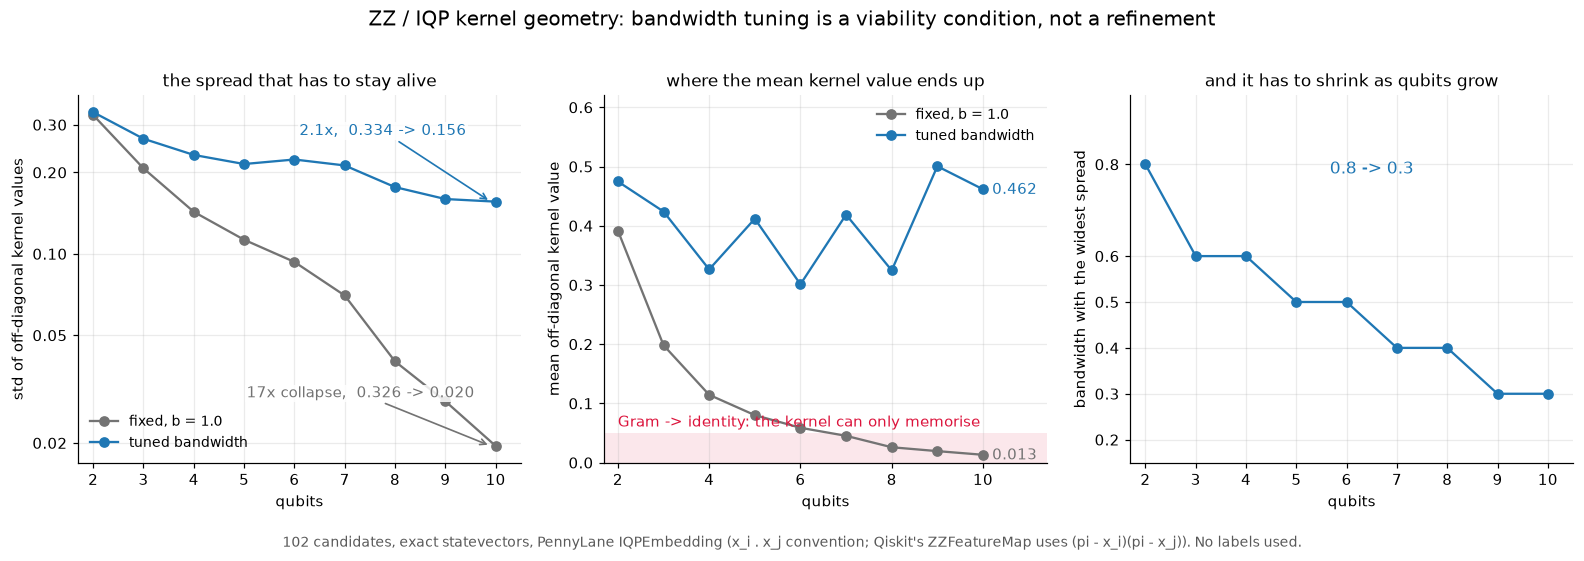

In [30]:
q = conc["n_qubits"].to_numpy()
f_fix = conc["std_b1"].iloc[0] / conc["std_b1"].iloc[-1]
f_tun = conc["std_tuned"].iloc[0] / conc["std_tuned"].iloc[-1]

fig, ax = plt.subplots(1, 3, figsize=(14.5, 4.6))

ax[0].plot(q, conc["std_b1"], "o-", color=C_FIX, label="fixed, b = 1.0")
ax[0].plot(q, conc["std_tuned"], "o-", color=C_TUN, label="tuned bandwidth")
ax[0].set(yscale="log", xlim=(1.7, 10.5), xlabel="qubits",
          ylabel="std of off-diagonal kernel values", title="the spread that has to stay alive")
ax[0].minorticks_off()
ax[0].set_yticks([0.02, 0.05, 0.1, 0.2, 0.3], ["0.02", "0.05", "0.10", "0.20", "0.30"])
ax[0].annotate(f"{f_fix:.0f}x collapse,  {conc['std_b1'].iloc[0]:.3f} -> {conc['std_b1'].iloc[-1]:.3f}",
               xy=(9.9, conc["std_b1"].iloc[-1]), xytext=(5.05, 0.0295), fontsize=9.5, color=C_FIX,
               bbox=dict(fc="white", ec="none", alpha=0.85, pad=1),
               arrowprops=dict(arrowstyle="->", color=C_FIX, lw=1.1))
ax[0].annotate(f"{f_tun:.1f}x,  {conc['std_tuned'].iloc[0]:.3f} -> {conc['std_tuned'].iloc[-1]:.3f}",
               xy=(9.9, conc["std_tuned"].iloc[-1]), xytext=(6.1, 0.275), fontsize=9.5, color=C_TUN,
               bbox=dict(fc="white", ec="none", alpha=0.85, pad=1),
               arrowprops=dict(arrowstyle="->", color=C_TUN, lw=1.1))
ax[0].legend(loc="lower left", fontsize=9)

ax[1].axhspan(0, 0.05, color="crimson", alpha=0.10, lw=0)
ax[1].text(2.0, 0.055, "Gram -> identity: the kernel can only memorise",
           color="crimson", fontsize=9.5, va="bottom")
ax[1].plot(q, conc["mean_b1"], "o-", color=C_FIX, label="fixed, b = 1.0")
ax[1].plot(q, conc["mean_tuned"], "o-", color=C_TUN, label="tuned bandwidth")
for col, c in (("mean_b1", C_FIX), ("mean_tuned", C_TUN)):
    ax[1].annotate(f"{conc[col].iloc[-1]:.3f}", xy=(q[-1], conc[col].iloc[-1]), xytext=(6, -3),
                   textcoords="offset points", ha="left", color=c, fontsize=9.5)
ax[1].set(xlim=(1.7, 11.4), ylim=(0, 0.62), xlabel="qubits",
          ylabel="mean off-diagonal kernel value", title="where the mean kernel value ends up")
ax[1].legend(loc="upper right", fontsize=9)

ax[2].plot(q, conc["best_band"], "o-", color=C_TUN)
ax[2].set(xlim=(1.7, 10.5), ylim=(0.15, 0.95), yticks=[0.2, 0.3, 0.4, 0.5, 0.6, 0.8],
          xlabel="qubits", ylabel="bandwidth with the widest spread",
          title="and it has to shrink as qubits grow")
ax[2].annotate(f"{conc['best_band'].iloc[0]:.1f} -> {conc['best_band'].iloc[-1]:.1f}",
               xy=(6.5, 0.78), ha="center", color=C_TUN, fontsize=11)

fig.suptitle("ZZ / IQP kernel geometry: bandwidth tuning is a viability condition, not a refinement",
             y=1.02, fontsize=13)
fig.text(0.5, -0.04, "102 candidates, exact statevectors, PennyLane IQPEmbedding (x_i . x_j convention; "
                     "Qiskit's ZZFeatureMap uses (pi - x_i)(pi - x_j)). No labels used.",
         ha="center", fontsize=9, color="0.35")
fig.tight_layout()
save(fig, "fig1_kernel_concentration.png")
plt.show()

### Figure 2 - the correlation matrix *is* the entangling graph

Same matrix as section 3, reordered by the linkage so the redundancy clusters land on the diagonal. The boxes are the multi-member clusters at |rho| >= 0.7, i.e. the pairs where an entangling gate represents something the data has.

21 of 528 pairs clear the cut, which is the ~25x depth saving, and here it's visible as just how much of the matrix is pale. The `raw_*` width block and the `spec_*` pair are the obvious ones; the `prof_skew` / `prof_kurt` / `prof_peak_snr` box in the corner is the same Group A problem figure 4 shows from the other side.

The contiguity assert is there because the boxes would be wrong if a cluster's members weren't adjacent in leaf order. It holds for this linkage, but I didn't want to assume it.

wrote fig2_correlation_blocks.png


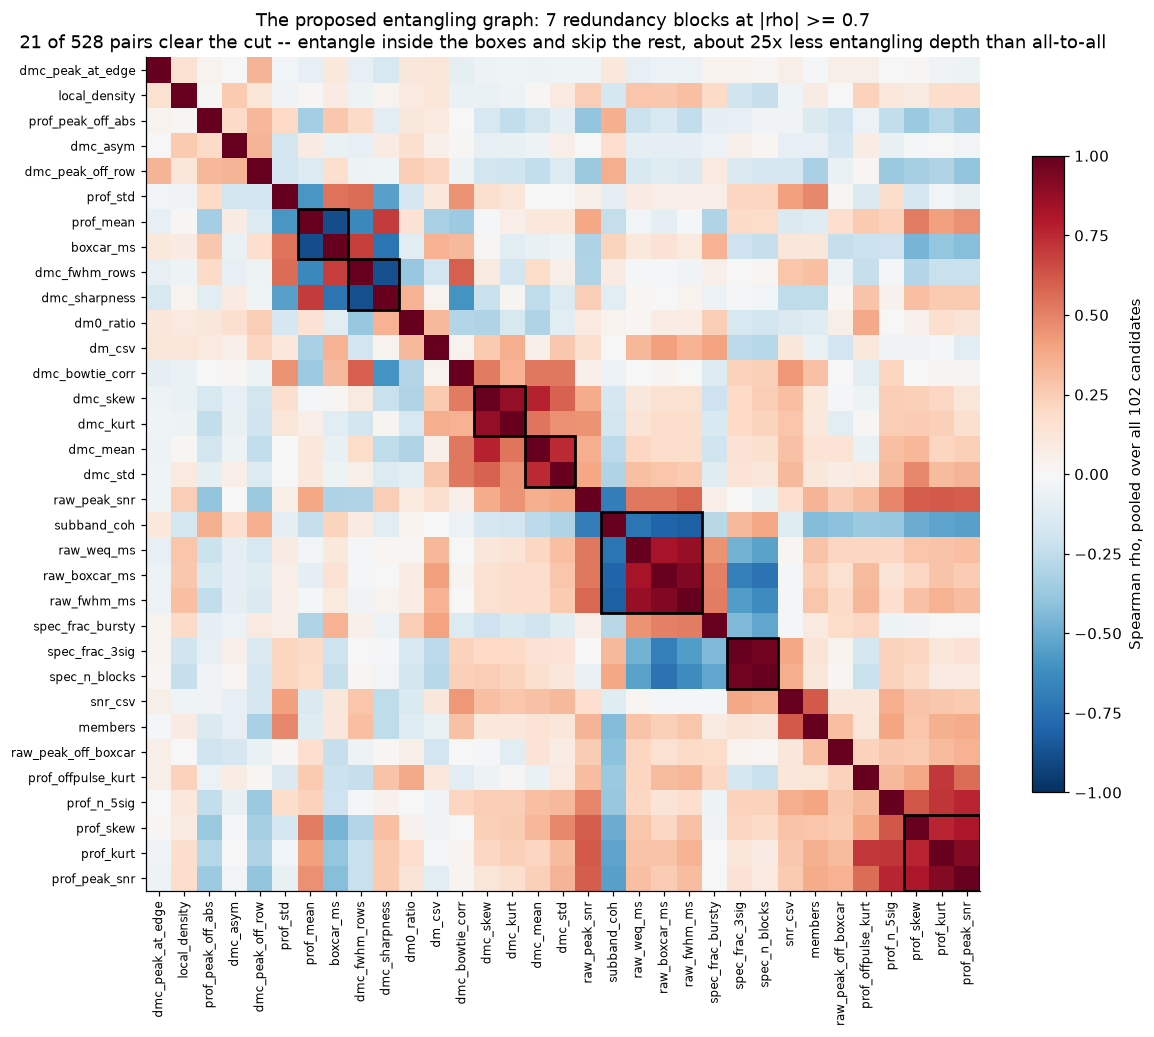

In [31]:
from scipy.cluster.hierarchy import leaves_list

order = leaves_list(Z)
labo = lab[order]
# a cluster has to be one contiguous run of leaves, or the boxes below would be lying
assert all((np.flatnonzero(labo == c).max() - np.flatnonzero(labo == c).min() + 1)
           == (labo == c).sum() for c in np.unique(labo)), "clusters are not contiguous in leaf order"

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(corr[np.ix_(order, order)], cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), [FEATURES[i] for i in order], rotation=90, fontsize=8)
ax.set_yticks(range(len(order)), [FEATURES[i] for i in order], fontsize=8)
ax.grid(False)

n_boxed = 0
for c in np.unique(labo):
    w = np.flatnonzero(labo == c)
    if len(w) > 1:
        ax.add_patch(Rectangle((w[0] - .5, w[0] - .5), len(w), len(w),
                               fill=False, ec="k", lw=1.8))
        n_boxed += 1

fig.colorbar(im, ax=ax, shrink=0.72, label="Spearman rho, pooled over all 102 candidates")
n_hi, n_all = int((pairs["absrho"] >= CUT).sum()), len(pairs)
ax.set_title(f"The proposed entangling graph: {n_boxed} redundancy blocks at |rho| >= {CUT}\n"
             f"{n_hi} of {n_all} pairs clear the cut -- entangle inside the boxes and skip the rest, "
             f"about {n_all / n_hi:.0f}x less entangling depth than all-to-all", fontsize=12)
fig.tight_layout()
save(fig, "fig2_correlation_blocks.png")
plt.show()

### Figure 3 - 4 directions, not 33 features

Bars are the eigenvalues of the rank correlation matrix. Red ones clear the Marchenko-Pastur edge at n = 102 (2.46); blue ones clear the edge the planned ~2,000-candidate pull would give (1.27) but not today's.

Both lines are drawn because the reading is "4 resolvable now, 6 at the pull's sample size", which is an argument for doing the pull *before* fixing the qubit count rather than for throwing 29 features away this week.

wrote fig3_eigenvalue_spectrum.png


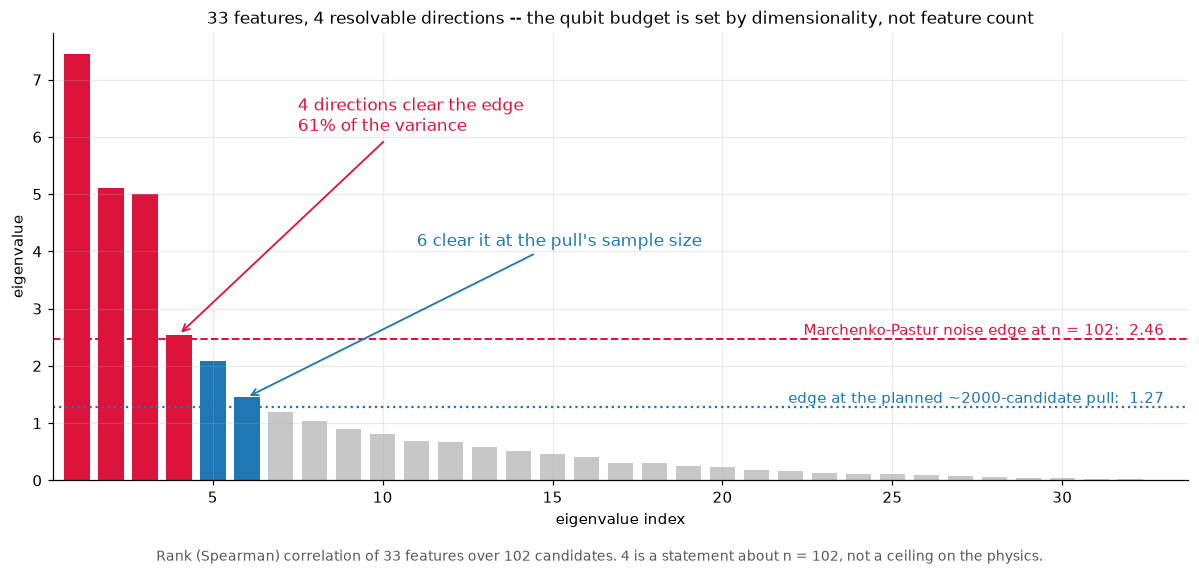

In [32]:
k = np.arange(1, len(ev) + 1)
n_pull = int((ev > edge_pull).sum())
col = np.where(ev > mp_edge, C_INJ, np.where(ev > edge_pull, C_TUN, "0.78"))

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(k, ev, color=col, width=0.75)
ax.axhline(mp_edge, color=C_INJ, ls="--", lw=1.3)
ax.axhline(edge_pull, color=C_TUN, ls=":", lw=1.5)
ax.text(len(ev), mp_edge + 0.08, f"Marchenko-Pastur noise edge at n = 102:  {mp_edge:.2f}",
        ha="right", color=C_INJ, fontsize=10)
ax.text(len(ev), edge_pull + 0.08, f"edge at the planned ~2000-candidate pull:  {edge_pull:.2f}",
        ha="right", color=C_TUN, fontsize=10)

ax.annotate(f"{n_real} directions clear the edge\n{100 * ev[:n_real].sum() / ev.sum():.0f}% of the variance",
            xy=(n_real, ev[n_real - 1]), xytext=(n_real + 3.5, ev[0] * 0.82), fontsize=11, color=C_INJ,
            arrowprops=dict(arrowstyle="->", color=C_INJ, lw=1.2))
ax.annotate(f"{n_pull} clear it at the pull's sample size",
            xy=(n_pull, ev[n_pull - 1]), xytext=(n_pull + 5, ev[0] * 0.55), fontsize=11, color=C_TUN,
            arrowprops=dict(arrowstyle="->", color=C_TUN, lw=1.2))

ax.set(xlabel="eigenvalue index", ylabel="eigenvalue", xlim=(0.3, len(ev) + 0.7),
       title=f"{len(FEATURES)} features, {n_real} resolvable directions -- the qubit budget is set by "
             f"dimensionality, not feature count")
fig.text(0.5, -0.03, "Rank (Spearman) correlation of 33 features over 102 candidates. "
                     "4 is a statement about n = 102, not a ceiling on the physics.",
         ha="center", fontsize=9, color="0.35")
fig.tight_layout()
save(fig, "fig3_eigenvalue_spectrum.png")
plt.show()

### Figure 4 - the disguise audit

Filled dots are within the 13 injections, open dots within the 89 negatives, one row per feature, sorted by whichever of the four is worst. The vertical lines are the simulated n = 13 null floor (95th 0.56, 99th 0.70) and the 0.85 restatement cut, so how much of the top of this plot is real and how much is what 13 points do by chance is readable off the same axis.

The Group A block is the callout. `prof_std`, `prof_skew` and `prof_kurt` sit at +0.956, +0.874 and +0.841 against S/N *inside the injections*. On a standardised profile those are three views of one amplitude, so spending three qubits and three rotation angles on them is spending depth three times on the same number.

It's drawn within class because, run pooled over all 102, the identical test flags only `members`. The gap between the class means swallows everything else. This caught me out and nearly cost the whole audit.

wrote fig4_disguise_audit.png


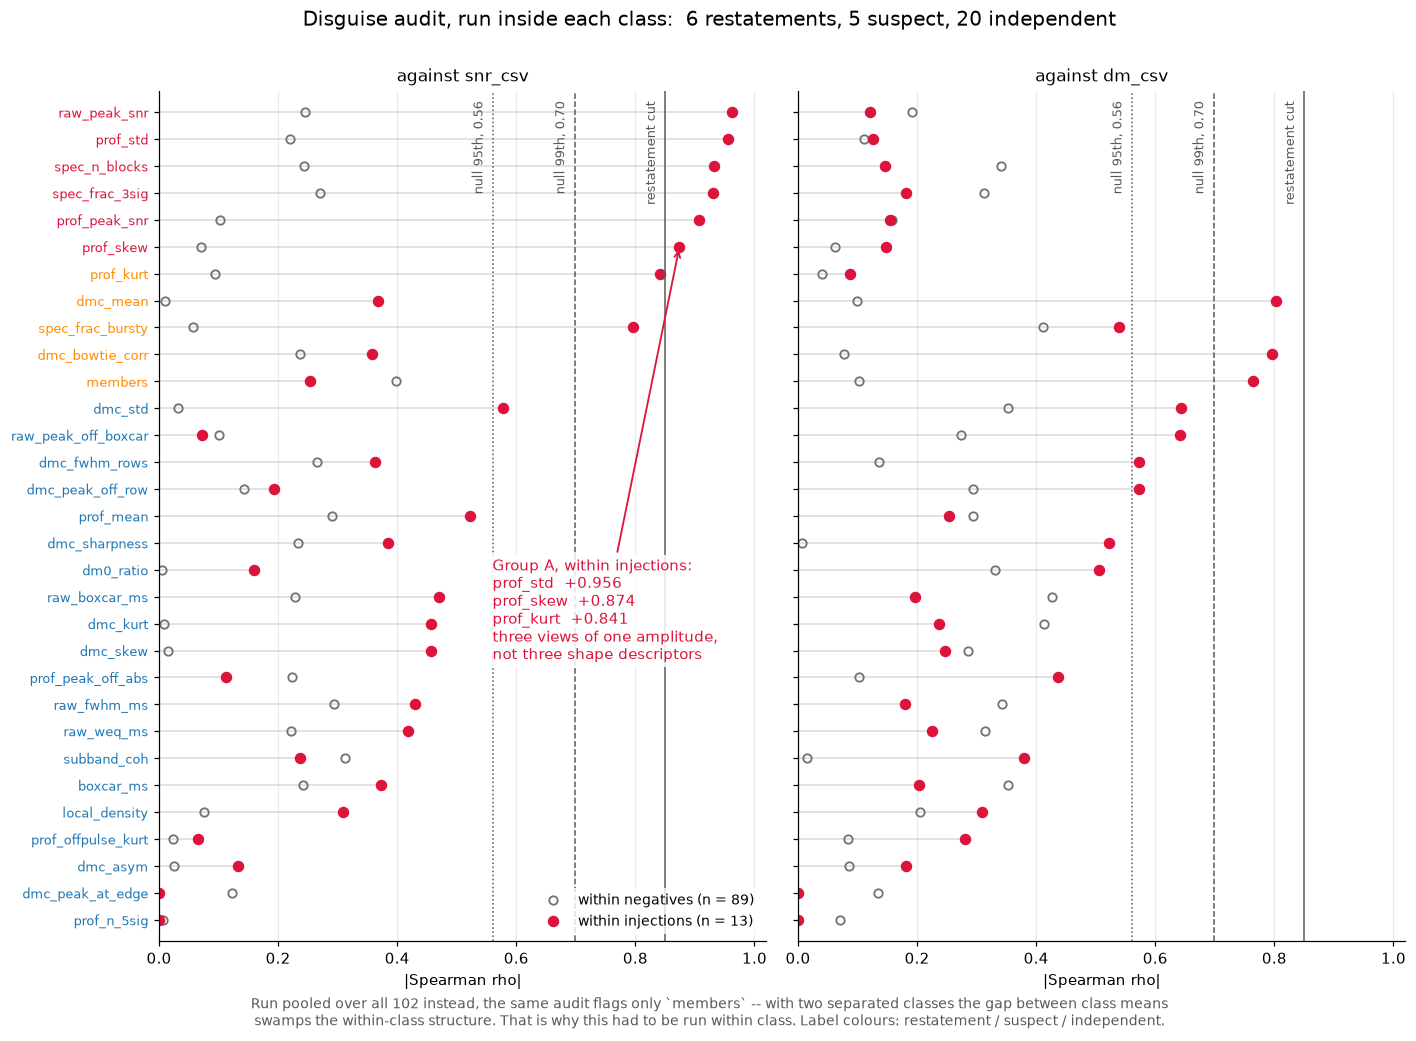

In [33]:
a = aud.sort_values("worst")                    # ascending, so the worst offenders land at the top
yv = np.arange(len(a))
q95, q99 = np.quantile(null, [0.95, 0.99])      # the n = 13 null floor simulated in section 1

fig, ax = plt.subplots(1, 2, figsize=(13, 9), sharey=True)
for k, (ci, cn, ref) in enumerate([("snr_inj", "snr_neg", "snr_csv"), ("dm_inj", "dm_neg", "dm_csv")]):
    ax[k].hlines(yv, 0, a[ci].abs(), color="0.88", lw=1.2, zorder=0)
    ax[k].plot(a[cn].abs(), yv, "o", ms=5.5, mfc="none", mew=1.2, color=C_NEG,
               label="within negatives (n = 89)")
    ax[k].plot(a[ci].abs(), yv, "o", ms=6.5, color=C_INJ, label="within injections (n = 13)")
    for x, ls, txt in [(q95, ":", f"null 95th, {q95:.2f}"), (q99, "--", f"null 99th, {q99:.2f}"),
                       (0.85, "-", "restatement cut")]:
        ax[k].axvline(x, color="0.35", ls=ls, lw=1)
        ax[k].text(x - 0.012, len(a) - 0.6, txt, rotation=90, fontsize=8.5, color="0.35",
                   va="top", ha="right")
    ax[k].set(xlim=(0, 1.02), xlabel="|Spearman rho|", title=f"against {ref}")
    ax[k].grid(axis="y", alpha=0)
ax[0].legend(loc="lower right", fontsize=9, frameon=True, facecolor="white", edgecolor="none")

ax[0].set_yticks(yv, a["feature"], fontsize=8.5)
for t, v in zip(ax[0].get_yticklabels(), a["verdict"]):
    t.set_color(C_VERDICT[v])
ax[0].set_ylim(-0.8, len(a) - 0.2)

ax[0].annotate("Group A, within injections:\nprof_std  +0.956\nprof_skew  +0.874\nprof_kurt  +0.841\n"
               "three views of one amplitude,\nnot three shape descriptors",
               xy=(0.874, int(np.flatnonzero(a["feature"].to_numpy() == "prof_skew")[0])),
               xytext=(0.56, 9.5), va="bottom", fontsize=9.5, color=C_INJ,
               bbox=dict(fc="white", ec="none", alpha=0.85, pad=2),
               arrowprops=dict(arrowstyle="->", color=C_INJ, lw=1.2))

n = aud["verdict"].value_counts()
fig.suptitle(f"Disguise audit, run inside each class:  {n['restatement']} restatements, "
             f"{n['suspect']} suspect, {n['independent']} independent", y=1.005, fontsize=13)
fig.text(0.5, -0.02, "Run pooled over all 102 instead, the same audit flags only `members` -- with two "
                     "separated classes the gap between class means\nswamps the within-class structure. "
                     "That is why this had to be run within class. Label colours: "
                     "restatement / suspect / independent.",
         ha="center", fontsize=9, color="0.35")
fig.tight_layout()
save(fig, "fig4_disguise_audit.png")
plt.show()

### Figure 5 - do the angles actually use their range

Open circles are the utilisation the spec's transform gives; blue dots are what promotion to quantile gives, and the bar between them is the fix. 7 features sat under 0.20: `members` at 0.124 and `prof_skew` at 0.127 were the worst, crushing every candidate into roughly an eighth of the available rotation. Median utilisation goes 0.341 -> 0.510.

The three flags are drawn as squares because they're exempt rather than broken. Two sit at 0.00 and `prof_n_5sig` sits at 1.00; for a binary both are the correct answer, and neither is something a transform should be asked to "fix".

wrote fig5_angle_utilisation.png


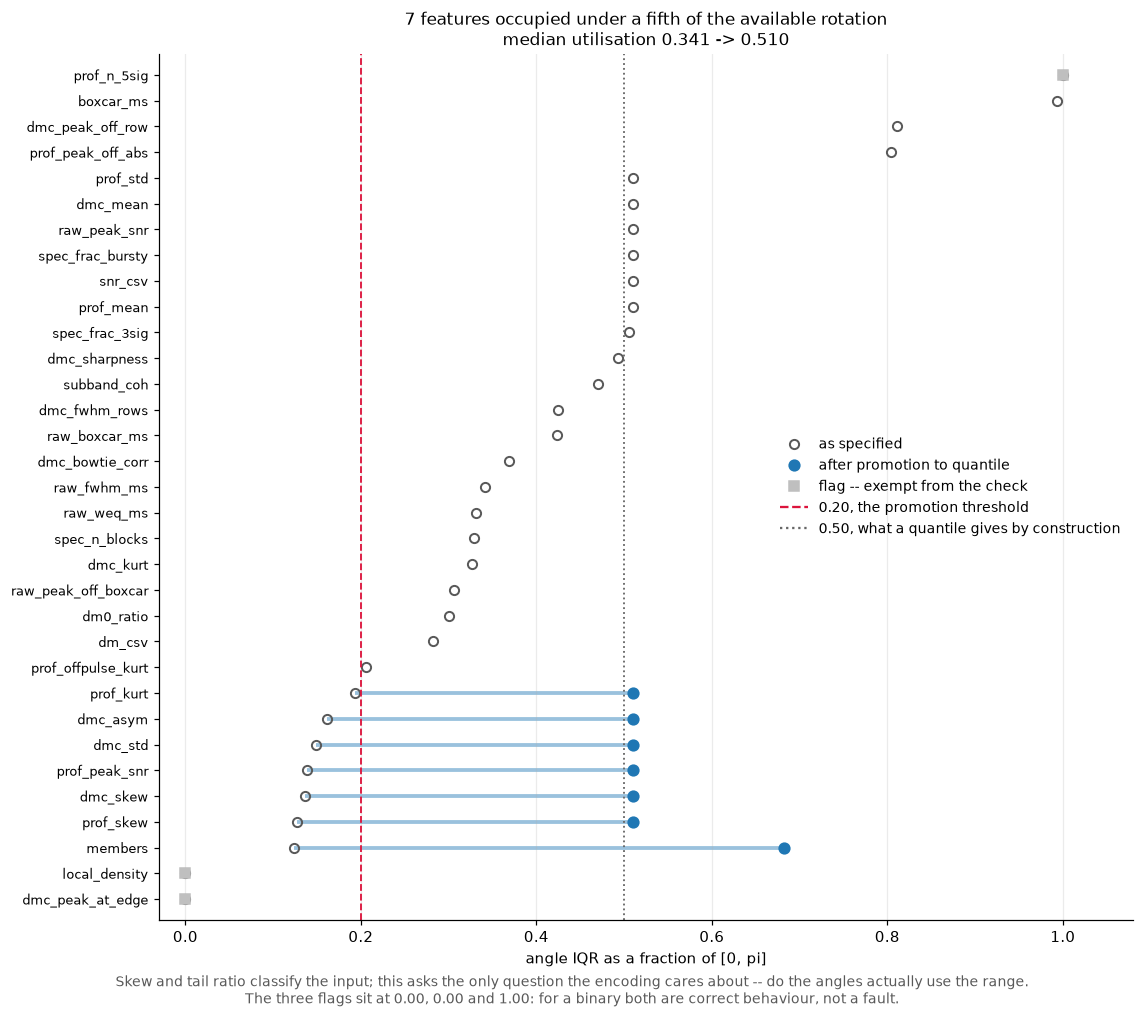

In [34]:
from matplotlib.lines import Line2D

uu = u.sort_values("util_before")
yv = np.arange(len(uu))
is_flag = uu["kind"].to_numpy() == "flag"
prom = uu["promoted"].to_numpy()

fig, ax = plt.subplots(figsize=(10.5, 9))
ax.hlines(yv[prom], uu.loc[prom, "util_before"], uu.loc[prom, "util_after"],
          color=C_TUN, lw=2.5, alpha=0.45, zorder=0)
ax.plot(uu["util_before"], yv, "o", ms=6, mfc="none", mew=1.3, color="0.35", label="as specified")
ax.plot(uu.loc[prom, "util_after"], yv[prom], "o", ms=7, color=C_TUN,
        label="after promotion to quantile")
ax.plot(uu.loc[is_flag, "util_before"], yv[is_flag], "s", ms=7, color="0.75",
        label="flag -- exempt from the check")
ax.axvline(0.20, color=C_INJ, ls="--", lw=1.2)
ax.axvline(0.50, color="0.4", ls=":", lw=1.2)

ax.set_yticks(yv, uu["feature"], fontsize=8.5)
ax.set_ylim(-0.8, len(uu) - 0.2)
ax.grid(axis="y", alpha=0)
ax.set(xlim=(-0.03, 1.08), xlabel="angle IQR as a fraction of [0, pi]",
       title=f"{int(prom.sum())} features occupied under a fifth of the available rotation\n"
             f"median utilisation {uu['util_before'].median():.3f} -> {uu['util_after'].median():.3f}")
ax.legend(handles=ax.get_legend_handles_labels()[0] + [
    Line2D([], [], color=C_INJ, ls="--", label="0.20, the promotion threshold"),
    Line2D([], [], color="0.4", ls=":", label="0.50, what a quantile gives by construction")],
    loc="center right", fontsize=9)
fig.text(0.5, -0.02, "Skew and tail ratio classify the input; this asks the only question the encoding "
                     "cares about -- do the angles actually use the range.\nThe three flags sit at 0.00, "
                     "0.00 and 1.00: for a binary both are correct behaviour, not a fault.",
         ha="center", fontsize=9, color="0.35")
fig.tight_layout()
save(fig, "fig5_angle_utilisation.png")
plt.show()

# Closing the EDA

Everything above answers a piece of the encoding question. This last section pulls the four notebooks together into the three things the group has to leave the room with: what this dataset turned out to *be*, which features are worth encoding, and what the next step needs from us.

### What the files claim, and what they actually are

These are the ordinary result of reading a pipeline's output as if it were measurement, and each one would have broken a feature if we'd trusted it.

| The files say | It's actually | Where |
|---|---|---|
| h5 `label` = 0 on all 102 | a placeholder. Ground truth is the TOA x DM cross-match against `inj_params.csv`: nothing the pipeline writes is truth | nb01 |
| FETCH `label` in `Results_MULTI.csv` | a *prediction*, `prob > 0.5`. `Results_MULTI` is the plain mean of the 11 models, to 2e-16. Training on it would cap us at FETCH | nb01 |
| h5 `*_decimation_factor` = 1, both axes | freq is **4** on all 102; time is **`max(1, boxcar_samples // 2)`**, matched exactly across all ten bins. `boxcar // 4` and `boxcar` both fail, which is what makes it evidence | nb01, nb03 §6 |
| h5 `nspectra` = 1,012,964 | the whole file's sample count, not the cutout's | nb02 |
| h5 `dm_opt`, `snr_opt` = -1 | sentinels. The log confirms `opt_dm: False` | nb02 |
| `az_start`, `za_start` = 1.0 | placeholders | nb01 |
| `SP_IDX` | a -999 sentinel, so there's no spectral-index truth to check anything against | nb01 |
| image `std` | **exactly 1.0 on all 102**: the whole spread is 2.2e-07, the last bits of a float32. It's a constant, which is why Group A is computed off 1-D collapsed curves | nb01, nb02 |
| `prof_mean` looks like a profile statistic | it equals the whole-image mean to 3.0e-08, because collapsing by mean is mean-preserving. The image mean itself spans 0.587 though, so it's **redundant, not dead** | nb04 §Group A |
| `Search_parameters.txt` / candmaker log: no RFI excision | true, but something upstream **equalised the gain**. Channel-mean spread is ~5 counts on 32,768, 0.016%. The `_processed` in the filename was accurate | nb03 §2 |
| 106 Heimdall candidates in `_all.cand` | 102 reach candmaker. The four dropped all sit at DM 10.6-11.05, on the `DM_LOW=10` floor. Not an S/N cut | nb01 |
| `width` | two conventions. `all_candidates.csv` `width` is **log2(boxcar)**; the h5 `width` attr is boxcar in **samples**. Mixing them up breaks the time axis | nb01 |

That's four separate attribute families that are placeholders, which is enough of a pattern that the working rule for the pull should be: **treat every attr as guilty until checked against something outside the file.**

### What the files don't say at all, and we had to establish

| Question | What we established | Where |
|---|---|---|
| how many samples in the `.fil` | no `nsamples` key, derived from file size, and the arithmetic closes with **0 bytes slack**, so shape and itemsize are forced | nb01, nb03 §1 |
| signed or unsigned | no `signed` key. `uint16` confirmed by **support contiguity** (24,876-65,535, no interior gap); native byte order confirmed at 1.0004x uniform-16-bit | nb03 §1 |
| where's the noise floor | a **~25,000-count DC pedestal**, not 0. Every threshold has to be baseline-relative, and `uint16` overflows the moment you sum over frequency | nb03 §1 |
| how much RFI, and where | **8 of 1024 channels**, narrowband, four discrete bursts under 280 ms. Removing them takes the worst block from 61.5 sigma to 3.8 sigma. **No injection window contains an event**, closest approach 0.114 s | nb03 §2-3 |
| what are the image axes | neither array carries coordinates. DM axis is `linspace(0, 2*dm, 256)`, so **row 0 is exactly DM 0**, which is what makes `dm0_ratio` exist at all. Time half-width is `sweep + boxcar*tsamp`, exact to a relative **2.35e-15** | nb02, nb03 §5 |
| which axis do I collapse | the two images are **transposed relative to each other**: `freq_time` is `[time, freq]`, `dm_time` is `[dm, time]`. Get it wrong and you get a plausible, meaningless curve and no error | nb02 |
| how do I collapse | profile takes **mean** over frequency; the DM-SNR curve takes **max** over time. `mean` there gives a flat line: ptp 0.15 against 34.36, a factor of 226 | nb02 |
| what is `tcand` referenced to | the **top** of the band. `ref='bottom'` puts the pulse 98.065% of the half-window off centre, i.e. on the edge. And the sweep needs `f_lo` = the last channel *centre* (401.054109 MHz) rather than the band edge, since the other reading is off by up to 5.20 ms | nb03 §5 |
| are the columns comparable across candidates | **no.** The window scales with DM (170 ms at DM 47, ~10 s at DM 2795), so any feature phrased in bins is a DM proxy. Everything here is in milliseconds | nb02 |
| is our dedispersion right | independent 15-line shift-and-sum agrees with Heimdall on **boxcar 64, exactly Heimdall's**, at S/N 48.71 vs 50.52, ratio 0.96, nothing tuned | nb03 §4 |
| where does the pipeline fail | Heimdall found **all 13**. FETCH rejected one at prob 0.219, the **widest** injection at 125.8 ms, needing 88.9% of the boxcar ceiling against 37.0% for the widest FETCH accepted. The only loss in the whole chain is the classifier, at the wide end | nb01, nb02 |

That last row is the most useful single object in the dataset, and it's the acceptance test I'd hold any feature set to: **a better feature set has to win on TOA 40.008 s or it hasn't beaten FETCH at anything.**

### The final feature list, and the rule that produces it

Four questions get asked in one pass, in this order, and each one is label-free:

| Step | Test | What it means |
|---|---|---|
| 1. reference axes | is it `snr_csv` or `dm_csv`? | keep. These are the physical quantities everything else was audited *against*, and they come free from Heimdall |
| 2. hidden variant | within-class \|rho\| > 0.85 against a reference | **drop.** It's a restatement of an axis we're already keeping |
| 3. cluster duplicate | not the representative of its redundancy cluster | **drop.** Its cluster is already on a qubit |
| 4. suspect | within-class \|rho\| in 0.70-0.85 | **hold.** Above the 99th-percentile null floor of 0.698, so not chance, but not a clean restatement either. This is the group's call, not mine |

The order of steps 2 and 3 is part of the rule: the restatements are dropped *because* we keep `snr_csv`. Representatives are chosen by communality on the four resolvable directions, which is why the surviving list comes out ranked rather than as a set.

**One thing to know about what you're buying at rank 3.** `prof_mean` is the image mean rather than a profile-shape quantity (see the Group A verdict above). It has real range and it's independent of both reference axes, so it passes every test here, but it's a normalisation-level statistic and anyone who wants to argue it off the register has a fair case. It's kept because the rule kept it, not because I'd defend it on physics.

In [35]:
# The final feature list. No new statistics here: this is bookkeeping over columns that already
# exist (verdict from the within-class disguise audit, cluster from the linkage, ORDER from
# communality on the resolvable directions), collapsed into one decision per feature.
REFERENCES = ["snr_csv", "dm_csv"]
DRIVER = {"snr_inj": "snr_csv", "snr_neg": "snr_csv", "dm_inj": "dm_csv", "dm_neg": "dm_csv"}

led = spec[["feature", "group", "verdict", "cluster", "kind", "transform"]].copy()
led = led.merge(aud[["feature"] + list(DRIVER)], on="feature", how="left")
rank = {f: i + 1 for i, f in enumerate(ORDER)}
rep_of = {cluster_of[f]: f for f in ORDER}
assert all(cluster_of[f] in rep_of for f in FEATURES
           if led.set_index("feature").loc[f, "verdict"] == "independent"), \
    "an independent feature sits in a cluster with no representative"

roles, reasons = [], []
for r in led.itertuples():
    w = np.abs([getattr(r, c) for c in DRIVER])
    drv = DRIVER[list(DRIVER)[int(np.nanargmax(w))]] if not np.all(np.isnan(w)) else ""
    if r.feature in REFERENCES:
        roles.append("reference")
        reasons.append("the axis every other feature was audited against")
    elif r.verdict == "restatement":
        roles.append("drop")
        reasons.append(f"hidden variant of {drv}, |rho| {np.nanmax(w):.2f} within class")
    elif r.verdict == "suspect":
        roles.append("hold")
        reasons.append(f"|rho| {np.nanmax(w):.2f} vs {drv} -- over the 0.70 null floor, under 0.85")
    elif r.feature in rank:
        roles.append("keep")
        reasons.append(f"representative of cluster {r.cluster}")
    else:
        roles.append("drop")
        reasons.append(f"duplicate of {rep_of[r.cluster]}, cluster {r.cluster}")
led["role"], led["reason"] = roles, reasons
led["register_rank"] = led["feature"].map(rank)

ORD = ["reference", "keep", "hold", "drop"]
led = (led.assign(_o=led["role"].map({r: i for i, r in enumerate(ORD)}))
          .sort_values(["_o", "register_rank", "feature"]).drop(columns="_o").reset_index(drop=True))

n0 = len(led)
n_res = int((led["verdict"] == "restatement").sum())
n_dup = int(((led["role"] == "drop") & (led["verdict"] != "restatement")).sum())
n_hold = int((led["role"] == "hold").sum())
n_keep = int((led["role"] == "keep").sum())
n_ref = int((led["role"] == "reference").sum())
assert n_res + n_dup + n_hold + n_keep + n_ref == n0

print(led[["feature", "group", "role", "register_rank", "cluster", "transform", "reason"]]
      .to_string(index=False, na_rep=""))
print(f"\n{n0} features"
      f"  -> drop {n_res} restatements -> {n0 - n_res}"
      f"  -> drop {n_dup} cluster duplicates -> {n0 - n_res - n_dup}"
      f"  -> hold {n_hold} suspect -> {n_keep + n_ref} encodable"
      f"  ({n_keep} cluster representatives + {n_ref} reference axes)")
print("\nnested register, first k of the communality order:")
for k in (4, 6, 8):
    print(f"  {k} qubits: " + ", ".join(ORDER[:k]))
print(f"\nheld for the group to settle: {led.loc[led['role'] == 'hold', 'feature'].tolist()}")
led.to_csv(OUT / "final_feature_ledger.csv", index=False)
print("\nwrote final_feature_ledger.csv")

            feature group      role  register_rank  cluster  transform                                                        reason
             dm_csv     E reference                      10       none              the axis every other feature was audited against
            snr_csv     E reference                      18   quantile              the axis every other feature was audited against
      raw_boxcar_ms B_raw      keep            1.0       14 signed-log                                  representative of cluster 14
           dmc_skew     A      keep            2.0       11   quantile                                  representative of cluster 11
          prof_mean     A      keep            3.0        6   quantile                                   representative of cluster 6
      dmc_fwhm_rows     C      keep            4.0        7 signed-log                                   representative of cluster 7
            dmc_std     A      keep            5.0       12   quantil

### Figure 6 - 33 computed, 16 worth a qubit

Left panel is the funnel with the reason for each cut. Right panel is the answer to "which features", in the order to spend qubits in: take the first *k* for a *k*-qubit register, and the two dashed lines are where Marchenko-Pastur says the information runs out, now and after the pull.

The caveat is in the caption: figure 1's kernel geometry was measured on exactly these 14, so if the group puts `snr_csv` and `dm_csv` back on the register (the rule above says to keep them, and the communality ranking never saw them), the geometry needs re-measuring on that list. It's a re-run of one cell rather than new work, but it isn't done here.

wrote fig6_feature_register.png


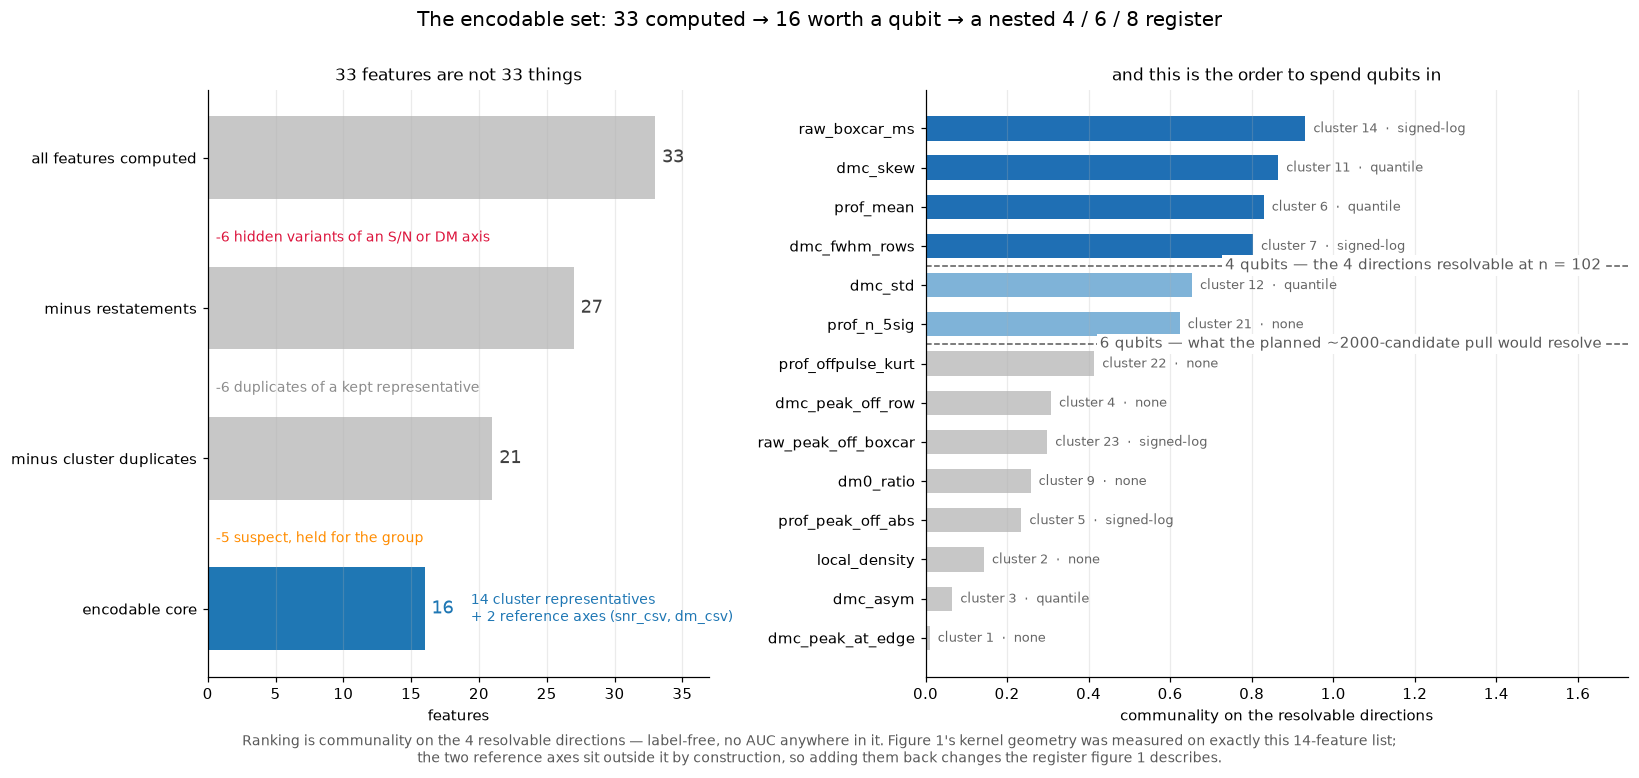

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6.6), gridspec_kw={"width_ratios": [1, 1.4]})

stages = [("all features computed", n0, "", "0.78"),
          ("minus restatements", n0 - n_res, f"-{n_res} hidden variants of an S/N or DM axis",
           C_VERDICT["restatement"]),
          ("minus cluster duplicates", n0 - n_res - n_dup,
           f"-{n_dup} duplicates of a kept representative", "0.55"),
          ("encodable core", n_keep + n_ref, f"-{n_hold} suspect, held for the group",
           C_VERDICT["suspect"])]
yy = np.arange(len(stages))[::-1]
ax[0].barh(yy, [s[1] for s in stages], color=["0.78", "0.78", "0.78", C_TUN], height=0.55)
for y, (lbl, n, note, c) in zip(yy, stages):
    ax[0].text(n + 0.5, y, str(n), va="center", fontsize=12,
               color=C_TUN if lbl.startswith("encodable") else "0.25")
    if note:
        ax[0].text(0.6, y + 0.42, note, va="bottom", fontsize=9, color=c)
ax[0].set_yticks(yy, [s[0] for s in stages], fontsize=10)
ax[0].set(xlim=(0, n0 + 4), xlabel="features", title="33 features are not 33 things")
ax[0].grid(axis="y", alpha=0)
ax[0].text(n_keep + n_ref + 3.4, yy[-1], f"{n_keep} cluster representatives\n+ {n_ref} reference axes "
                                         f"(snr_csv, dm_csv)", fontsize=9, color=C_TUN, va="center")

comm = np.array([communality[FEATURES.index(f)] for f in ORDER])
yr = np.arange(len(ORDER))[::-1]
band = ["#1f6fb4"] * 4 + ["#7fb3d8"] * 2 + ["0.78"] * (len(ORDER) - 6)
ax[1].barh(yr, comm, color=band, height=0.62)
for y, f, c in zip(yr, ORDER, comm):
    row = led.set_index("feature").loc[f]
    ax[1].text(c + 0.02, y, f"cluster {int(row['cluster'])}  ·  {row['transform']}",
               va="center", fontsize=8.5, color="0.4")
for k, txt in ((4, f"4 qubits — the {n_real} directions resolvable at n = 102"),
               (6, "6 qubits — what the planned ~2000-candidate pull would resolve")):
    ax[1].axhline(yr[k - 1] - 0.5, color="0.35", ls="--", lw=1)
    ax[1].text(comm.max() * 1.78, yr[k - 1] - 0.5, txt, fontsize=9.5, color="0.35",
               ha="right", va="center", bbox=dict(fc="white", ec="none", pad=2))
ax[1].set_yticks(yr, ORDER, fontsize=9.5)
ax[1].set(xlim=(0, comm.max() * 1.85), xlabel="communality on the resolvable directions",
          title="and this is the order to spend qubits in")
ax[1].grid(axis="y", alpha=0)

fig.suptitle(f"The encodable set: {n0} computed → {n_keep + n_ref} worth a qubit → a nested "
             f"4 / 6 / 8 register", y=1.005, fontsize=13)
fig.text(0.5, -0.03, "Ranking is communality on the 4 resolvable directions — label-free, no AUC "
                     "anywhere in it. Figure 1's kernel geometry was measured on exactly this "
                     f"{len(ORDER)}-feature list;\nthe two reference axes sit outside it by "
                     "construction, so adding them back changes the register figure 1 describes.",
         ha="center", fontsize=9, color="0.35")
fig.tight_layout()
save(fig, "fig6_feature_register.png")
plt.show()

### What the next step needs from this EDA

Splitting this by what's settled and what's blocked, because they need different things from the group.

**Settled, and it transfers.** All of it is label-free, which is the only reason I'd carry it across to a different observation.

| What | Value |
|---|---|
| transform + `[0, pi]` constants, per feature | `encoding_spec.csv`: 9 log-fixable, 7 well-behaved, 7 stubborn, 7 promoted to quantile, 3 flags |
| angle utilisation, after the fix | median 0.341 -> 0.510; 7 features promoted to quantile |
| redundancy graph | 21 of 528 pairs above \|rho\| >= 0.7, in 7 blocks: entangle inside the blocks only |
| dimensionality | 4 resolvable directions at n = 102, 60.9% of variance; ~6 at the pull's n |
| kernel geometry | ZZ/IQP is viable **only** with bandwidth tuning: 17x spread collapse vs 2.1x, bandwidth 0.8 -> 0.3 |
| re-uploading depth | `r = 1`. 16 of 33 features flip across CV seeds, so nothing deeper is supported |
| the final list | `final_feature_ledger.csv`: 16 encodable, 12 dropped with a named parent, 5 held |

**Blocked on the pull, and nothing here can unblock it.** Every question about how *useful* a feature is needs labels, and 13 injections in one clean observation cannot answer it. `snr_csv` scores AUC 1.000, `members` 0.999, and nb03's `dm0_raw` hit 1.000 purely by being `1/S/N` in disguise. So: no feature ranking, no separability claim, no "best k" from this notebook.

**What I'd put on the agenda, in order:**

1. **Do the pull** (~2,000 candidates over the 20 observations) before fixing the qubit count. It moves the MP edge from 2.46 to 1.27, at which 6 of the current directions already clear.
2. **Re-run the label-free half on it.** The constants will move; the method won't. The deliverable of this EDA is that procedure.
3. **Settle the 5 held features.** `dmc_bowtie_corr`, `dmc_mean`, `members`, `prof_kurt`, `spec_frac_bursty`. All sit in 0.70-0.85 against a reference axis.
4. **Decide the register.** 4-6 qubits, nested per figure 6. Bandwidth isn't optional: ~0.6 at 4, ~0.5 at 5-6.
5. **Keep the classical baseline as the HTRU-2 analogue.** All 8 Group A features stay in the classical arm even though the encoding drops 3 of them, otherwise the comparison isn't a comparison. This is the one place "drop" does not propagate.

**Not measured here**, so nobody presents it as if it were: plain angle / product-state encoding has no measured geometry (its row in the families table is reasoning, not data), and the same goes for amplitude encoding and QAUM. No encoding was tested for whether it *preserves* class structure, only for whether it degenerates. That test needs the pull, and it belongs to the modelling step rather than to the EDA.